<a href="https://colab.research.google.com/github/mejian1/ExopherGeneExpressionProfiling/blob/main/ZB5886_Touch_Neuron_TRAPseq_Colab_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Touch Neuron-Specific TRAP-Seq Bioinformatic Pipeline (`ZB5886`)
### Identifying Translational Regulators of Exopher Production in *C. elegans* on Google Colab

**Experimental Design (Yongzhi Yang, 09-14-2026):**
- **Strain (`ZB5886`):** `bzIs166[Pmec-4::mCherry]; bzIs228[mec-18p::3XFLAG::rpl-22::SL2::wrmScarlet::rab-3 3'UTR]`
- **Assay:** Translating Ribosome Affinity Purification sequencing (TRAP-seq; Wester et al., *Cell Reports*, 2023) following cycloheximide stabilization of ribosome-bound mRNAs in mechanosensory touch receptor neurons (ALML, ALMR, AVM, PVM, PLML, PLMR).
- **Sequencing Platform:** Element Biosciences AVITI (Lanes 1+2 combined, Paired-End 2 × 75 bp, demultiplexed via `bases2fastq`).
- **Cohort Structure (30 Samples, `#95–124`):**
  - **5 Developmental/Adulthood Stages:** `L4`, `D1`, `D2` (exopher peak), `D3`, `D4`
  - **2 RNAi Conditions:** Control `Luciferase` RNAi (normal exopher induction peaking at D2) vs. Suppressor `cbd-1` RNAi (basal aging/development without exopher induction; Wang et al., *eLife*, 2024)
  - **3 Biological Repeats:** `Repeat_1`, `Repeat_2`, `Repeat_3` (150,000 worms per sample)

---
### Why This Runs Smoothly on Google Colab
1. **Low RAM Footprint (~2–4 GB):** Because the *C. elegans* (`WBcel235`) genome is only ~100 Mb, scaling `STAR` to `--genomeSAindexNbases 12` reduces memory usage from ~32 GB (mammalian) to **<4 GB RAM**, allowing full splice-aware alignment even on **free-tier Google Colab (12.7 GB RAM)**.
2. **Drive Checkpointing & Resumability:** Raw FASTQs stay on Google Drive, one sample pair at a time is processed on Colab's fast local SSD (`/content/tmp_work`), and completed count tables + QC logs are saved immediately to Google Drive. If a session disconnects, re-running the loop automatically resumes where it left off.

## Step 1: Mount Google Drive, Configure Directories & Build the 30-Sample Manifest
Update `FASTQ_DIR` below to point to the Google Drive folder containing your 60 demultiplexed `.fastq.gz` files (`_R1` and `_R2` for Samples 95–124).

In [1]:
import os
import glob
import shutil
import subprocess
import pandas as pd
import numpy as np

# Mount Google Drive when running inside Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab; using local ./colab_workspace directory.")

BASE_DRIVE_DIR = '/content/drive/MyDrive/ZB5886_TRAPseq' if IN_COLAB else './colab_workspace'
# Updated directory pointing to verified path from recursive search
FASTQ_DIR      = '/content/drive/MyDrive/Sequencing files_092326' if IN_COLAB else './colab_workspace'
INDEX_CACHE    = f'{BASE_DRIVE_DIR}/STAR_Index_WBcel235_ZB5886'
COUNTS_DIR     = f'{BASE_DRIVE_DIR}/Counts_Per_Sample'
QC_DIR         = f'{BASE_DRIVE_DIR}/QC_Logs'
RESULTS_DIR    = f'{BASE_DRIVE_DIR}/DESeq2_Results'
LOCAL_WORK     = '/content/tmp_work'
LOCAL_REF      = '/content/ref'
LOCAL_INDEX    = '/content/star_index'

for d in [BASE_DRIVE_DIR, COUNTS_DIR, QC_DIR, RESULTS_DIR, LOCAL_WORK, LOCAL_REF, LOCAL_INDEX]:
    os.makedirs(d, exist_ok=True)

THREADS = max(2, os.cpu_count() or 2)
print(f"Configured pipeline with {THREADS} CPU threads.")
print(f"FASTQ input directory: {FASTQ_DIR}")
print(f"Persistent output directory: {BASE_DRIVE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Configured pipeline with 24 CPU threads.
FASTQ input directory: /content/drive/MyDrive/Sequencing files_092326
Persistent output directory: /content/drive/MyDrive/ZB5886_TRAPseq


In [2]:
# Build the official 30-Sample Run Manifest (Samples 95–124 from Element Biosciences AVITI Lanes 1+2)
manifest_rows = [
    (95,  "Repeat_1_ZB5886_Luciferase_L4",    "Repeat_1", "Luciferase", "L4", "ACTCGCTA", "CTCTCTAT", 23975662, 3.644005, "Pass"),
    (96,  "Repeat_1_ZB5886_Luciferase_Day_1", "Repeat_1", "Luciferase", "D1", "ACTCGCTA", "TATCCTCT", 24878985, 3.781296, "Pass"),
    (97,  "Repeat_1_ZB5886_Luciferase_Day_2", "Repeat_1", "Luciferase", "D2", "ACTCGCTA", "GTAAGGAG", 23293283, 3.540293, "Pass"),
    (98,  "Repeat_1_ZB5886_Luciferase_Day_3", "Repeat_1", "Luciferase", "D3", "ACTCGCTA", "ACTGCATA", 39296313, 5.972548, "Pass"),
    (99,  "Repeat_1_ZB5886_Luciferase_Day_4", "Repeat_1", "Luciferase", "D4", "ACTCGCTA", "AAGGAGTA", 31010333, 4.713181, "Pass"),
    (100, "Repeat_2_ZB5886_Luciferase_L4",    "Repeat_2", "Luciferase", "L4", "ACTCGCTA", "CTAAGCCT", 31591276, 4.801470, "Pass"),
    (101, "Repeat_2_ZB5886_Luciferase_Day_1", "Repeat_2", "Luciferase", "D1", "ACTCGCTA", "CGTCTAAT", 18260396, 2.775361, "Pass"),
    (102, "Repeat_2_ZB5886_Luciferase_Day_2", "Repeat_2", "Luciferase", "D2", "ACTCGCTA", "TCTCTCCG", 21684568, 3.295787, "Pass"),
    (103, "Repeat_2_ZB5886_Luciferase_Day_3", "Repeat_2", "Luciferase", "D3", "GGAGCTAC", "CTCTCTAT",  3072700, 0.467006, "LOW_DEPTH_OUTLIER"),
    (104, "Repeat_2_ZB5886_Luciferase_Day_4", "Repeat_2", "Luciferase", "D4", "GGAGCTAC", "TATCCTCT", 42971713, 6.530530, "Pass"),
    (105, "Repeat_3_ZB5886_Luciferase_L4",    "Repeat_3", "Luciferase", "L4", "GGAGCTAC", "GTAAGGAG", 20115024, 3.057223, "Pass"),
    (106, "Repeat_3_ZB5886_Luciferase_Day_1", "Repeat_3", "Luciferase", "D1", "GGAGCTAC", "ACTGCATA", 26652701, 4.050875, "Pass"),
    (107, "Repeat_3_ZB5886_Luciferase_Day_2", "Repeat_3", "Luciferase", "D2", "GGAGCTAC", "AAGGAGTA", 26888454, 4.086697, "Pass"),
    (108, "Repeat_3_ZB5886_Luciferase_Day_3", "Repeat_3", "Luciferase", "D3", "GGAGCTAC", "CTAAGCCT", 27215628, 4.136430, "Pass"),
    (109, "Repeat_3_ZB5886_Luciferase_Day_4", "Repeat_3", "Luciferase", "D4", "GGAGCTAC", "CGTCTAAT", 25092750, 3.813740, "Pass"),
    (110, "Repeat_1_ZB5886_cbd_1_RNAi_L4",    "Repeat_1", "cbd_1_RNAi", "L4", "GGAGCTAC", "TCTCTCCG", 24805263, 3.770098, "Pass"),
    (111, "Repeat_1_ZB5886_cbd_1_RNAi_Day_1", "Repeat_1", "cbd_1_RNAi", "D1", "GCGTAGTA", "CTCTCTAT", 23409138, 3.557902, "Pass"),
    (112, "Repeat_1_ZB5886_cbd_1_RNAi_Day_2", "Repeat_1", "cbd_1_RNAi", "D2", "GCGTAGTA", "TATCCTCT", 21784751, 3.311011, "Pass"),
    (113, "Repeat_1_ZB5886_cbd_1_RNAi_Day_3", "Repeat_1", "cbd_1_RNAi", "D3", "GCGTAGTA", "GTAAGGAG", 24048627, 3.655098, "Pass"),
    (114, "Repeat_1_ZB5886_cbd_1_RNAi_Day_4", "Repeat_1", "cbd_1_RNAi", "D4", "GCGTAGTA", "ACTGCATA", 23039735, 3.501760, "Pass"),
    (115, "Repeat_2_ZB5886_cbd_1_RNAi_L4",    "Repeat_2", "cbd_1_RNAi", "L4", "GCGTAGTA", "AAGGAGTA", 25416544, 3.863001, "Pass"),
    (116, "Repeat_2_ZB5886_cbd_1_RNAi_Day_1", "Repeat_2", "cbd_1_RNAi", "D1", "GCGTAGTA", "CTAAGCCT", 21554562, 3.276025, "Pass"),
    (117, "Repeat_2_ZB5886_cbd_1_RNAi_Day_2", "Repeat_2", "cbd_1_RNAi", "D2", "GCGTAGTA", "CGTCTAAT", 27640203, 4.200965, "Pass"),
    (118, "Repeat_2_ZB5886_cbd_1_RNAi_Day_3", "Repeat_2", "cbd_1_RNAi", "D3", "GCGTAGTA", "TCTCTCCG", 16345061, 2.484252, "Pass"),
    (119, "Repeat_2_ZB5886_cbd_1_RNAi_Day_4", "Repeat_2", "cbd_1_RNAi", "D4", "CGGAGCCT", "CTCTCTAT", 21209240, 3.223542, "Pass"),
    (120, "Repeat_3_ZB5886_cbd_1_RNAi_L4",    "Repeat_3", "cbd_1_RNAi", "L4", "CGGAGCCT", "TATCCTCT", 29085951, 4.420646, "Pass"),
    (121, "Repeat_3_ZB5886_cbd_1_RNAi_Day_1", "Repeat_3", "cbd_1_RNAi", "D1", "CGGAGCCT", "GTAAGGAG", 36059811, 5.480616, "Pass"),
    (122, "Repeat_3_ZB5886_cbd_1_RNAi_Day_2", "Repeat_3", "cbd_1_RNAi", "D2", "CGGAGCCT", "ACTGCATA", 27897265, 4.239957, "Pass"),
    (123, "Repeat_3_ZB5886_cbd_1_RNAi_Day_3", "Repeat_3", "cbd_1_RNAi", "D3", "CGGAGCCT", "AAGGAGTA", 32640063, 4.960874, "Pass"),
    (124, "Repeat_3_ZB5886_cbd_1_RNAi_Day_4", "Repeat_3", "cbd_1_RNAi", "D4", "CGGAGCCT", "CTAAGCCT", 28736513, 4.367530, "Pass"),
]

manifest_df = pd.DataFrame(
    manifest_rows,
    columns=["SampleNumber", "SampleName", "Repeat", "Condition", "Stage", "I1", "I2", "NumPoloniesAssigned", "Yield_Gb", "QC_Flag"]
)
manifest_df["Group"] = manifest_df["Condition"] + "_" + manifest_df["Stage"]
manifest_csv = f"{BASE_DRIVE_DIR}/ZB5886_30Sample_Manifest.csv"
manifest_df.to_csv(manifest_csv, index=False)

print("Saved 30-sample manifest to:", manifest_csv)
display(manifest_df.style.apply(
    lambda r: ["background-color: #FEE2E2; font-weight: bold" if r["QC_Flag"] == "LOW_DEPTH_OUTLIER" else "" for _ in r],
    axis=1
))

Saved 30-sample manifest to: /content/drive/MyDrive/ZB5886_TRAPseq/ZB5886_30Sample_Manifest.csv


,SampleNumber,SampleName,Repeat,Condition,Stage,I1,I2,NumPoloniesAssigned,Yield_Gb,QC_Flag,Group
0,95,Repeat_1_ZB5886_Luciferase_L4,Repeat_1,Luciferase,L4,ACTCGCTA,CTCTCTAT,23975662,3.644005,Pass,Luciferase_L4
1,96,Repeat_1_ZB5886_Luciferase_Day_1,Repeat_1,Luciferase,D1,ACTCGCTA,TATCCTCT,24878985,3.781296,Pass,Luciferase_D1
2,97,Repeat_1_ZB5886_Luciferase_Day_2,Repeat_1,Luciferase,D2,ACTCGCTA,GTAAGGAG,23293283,3.540293,Pass,Luciferase_D2
3,98,Repeat_1_ZB5886_Luciferase_Day_3,Repeat_1,Luciferase,D3,ACTCGCTA,ACTGCATA,39296313,5.972548,Pass,Luciferase_D3
4,99,Repeat_1_ZB5886_Luciferase_Day_4,Repeat_1,Luciferase,D4,ACTCGCTA,AAGGAGTA,31010333,4.713181,Pass,Luciferase_D4
5,100,Repeat_2_ZB5886_Luciferase_L4,Repeat_2,Luciferase,L4,ACTCGCTA,CTAAGCCT,31591276,4.801470,Pass,Luciferase_L4
6,101,Repeat_2_ZB5886_Luciferase_Day_1,Repeat_2,Luciferase,D1,ACTCGCTA,CGTCTAAT,18260396,2.775361,Pass,Luciferase_D1
7,102,Repeat_2_ZB5886_Luciferase_Day_2,Repeat_2,Luciferase,D2,ACTCGCTA,TCTCTCCG,21684568,3.295787,Pass,Luciferase_D2
8,103,Repeat_2_ZB5886_Luciferase_Day_3,Repeat_2,Luciferase,D3,GGAGCTAC,CTCTCTAT,3072700,0.467006,LOW_DEPTH_OUTLIER,Luciferase_D3
9,104,Repeat_2_ZB5886_Luciferase_Day_4,Repeat_2,Luciferase,D4,GGAGCTAC,TATCCTCT,42971713,6.530530,Pass,Luciferase_D4


## Step 2: Install `STAR`, `featureCounts` (`subread`), `samtools`, `fastp`, `FastQC`, `MultiQC` & `PyDESeq2`
Uses pre-compiled Ubuntu binaries (`apt-get`) so installation finishes in ~15–25 seconds without waiting for Conda environment solving.

In [3]:
%%bash
apt-get update -qq
apt-get install -y -qq rna-star subread samtools fastp fastqc
pip install -q multiqc pydeseq2 gseapy seaborn "pandas<3.0"

echo "=== Installed Tool Versions ==="
STAR --version
featureCounts -v
fastp --version
samtools --version | head -n 1

=== Installed Tool Versions ===
2.7.11b
samtools 1.19.2


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

featureCounts v2.0.6

fastp 0.23.4


## Step 3: Download WormBase `WBcel235` Reference, Add Custom Transgenes & Build `STAR` Index
1. Downloads the official *C. elegans* `WBcel235` genome assembly (`FASTA`) and gene models (`GTF`, Ensembl release 112 / WormBase).
2. Appends custom synthetic chromosomes/contigs for your `ZB5886` transgene reporters (`wrmScarlet`, `mCherry`, `3XFLAG_tag`) and the control RNAi feeding sequence (`Photinus_pyralis_Luciferase`) so they are quantified alongside endogenous WormBase genes.
3. Builds the `STAR` genome index with `--genomeSAindexNbases 12` (required for the ~100 Mb *C. elegans* genome) and caches it to Google Drive so future Colab sessions can load the index in seconds.

In [4]:
import os
import shutil
import subprocess

fa_path  = f"{LOCAL_REF}/WBcel235_plus_ZB5886_transgenes.fa"
gtf_path = f"{LOCAL_REF}/WBcel235_plus_ZB5886_transgenes.gtf"

if os.path.exists(f"{INDEX_CACHE}/SA"):
    print(f"[CACHE HIT] Copying pre-built STAR index from Google Drive ({INDEX_CACHE})...")
    shutil.copytree(INDEX_CACHE, LOCAL_INDEX, dirs_exist_ok=True)
    shutil.copy(f"{INDEX_CACHE}/WBcel235_plus_ZB5886_transgenes.gtf", gtf_path)
    print("STAR index and GTF ready in local SSD!")
else:
    print("[1/3] Downloading C. elegans WBcel235 FASTA and GTF from Ensembl/WormBase...")
    subprocess.run(
        f"wget -qO- https://ftp.ensembl.org/pub/release-112/fasta/caenorhabditis_elegans/dna/Caenorhabditis_elegans.WBcel235.dna.toplevel.fa.gz | gunzip -c > {fa_path}",
        shell=True, check=True
    )
    subprocess.run(
        f"wget -qO- https://ftp.ensembl.org/pub/release-112/gtf/caenorhabditis_elegans/Caenorhabditis_elegans.WBcel235.112.gtf.gz | gunzip -c > {gtf_path}",
        shell=True, check=True
    )

    print("[2/3] Appending ZB5886 custom transgene & Luciferase control contigs (replace placeholder sequences with exact plasmid sequences if desired)...")
    custom_contigs = {
        "TRANSGENE_3XFLAG_RPL22_TAG": (
            "WBGene_3XFLAG_rpl22",
            "3XFLAG_rpl22_bait",
            "ATGGACTACAAAGACCATGACGGTGATTATAAAGATCATGACATCGATTACAAGGATGACGATGACAAG"
        ),
        "TRANSGENE_wrmScarlet": (
            "WBGene_wrmScarlet",
            "wrmScarlet",
            "ATGGTCAGCAAGGGAGAGGCCGTCATCAAGGAGTTCATGCGCTTCAAGGTCCACATGGAGGGCTCCATGAACGGCCACGAGTTCGAGATCGAGGGCGAGGGCGAGGGCCGCCCCTACGAGGGCACCCAGACCGCCAAGCTGAAGGTGACCAAGGGTGGCCCCCTGCCCTTCTCCTGGGACATCCTGTCCCCTCAGTTCATGTACGGCTCCAAGGCCTACGTGAAGCACCCCGCCGACATCCCCGACTACTTGAAG"
        ),
        "TRANSGENE_mCherry": (
            "WBGene_mCherry",
            "mCherry",
            "ATGGTGAGCAAGGGCGAGGAGGATAACATGGCCATCATCAAGGAGTTCATGCGCTTCAAGGTGCACATGGAGGGCTCCGTGAACGGCCACGAGTTCGAGATCGAGGGCGAGGGCGAGGGCCGCCCCTACGAGGGCACCCAGACCGCCAAGCTGAAGGTGACCAAGGGTGGCCCCCTGCCCTTCGCCTGGGACATCCTGTCCCCTCAGTTCATGTACGGCTCCAAGGCCTACGTGAAGCACCCCGCCGACATCCCCGACTACTTGAAG"
        ),
        "CONTROL_RNAi_Luciferase": (
            "WBGene_Luciferase_dsRNA",
            "Luciferase_dsRNA",
            "ATGGAAGACGCCAAAAACATAAAGAAAGGCCCGGCGCCATTCTATCCGCTGGAAGATGGAACCGCTGGAGAGCAACTGCATAAGGCTATGAAGAGATACGCCCTGGTTCCTGGAACAATTGCTTTTACAGATGCACATATCGAGGTGGACATCACTTACGCTGAGTACTTCGAAATGTCCGTTCGGTTGGCAGAAGCTATGAAACGATATGGGCTGAATACAAATCACAGAATCGTCGTATGCAGTGAAAACTCTCTTCAATTCTTTATGCCGGTGTTGGGCGCGTTATTTATCGGAGTTGCAGTTGCGCCCGCGAACGACATTTATAATGAACGTGAATTGCTCAACAGTATGGGCATTTCGCAGCCTACCGTGGTGTTCGTTTCCAAAAAGGGGTTGCAAAAAATTTTGAACGTGCAAAAAAAGCTCCCAATCATCCAAAAAATTATTATCATGGATTCTAAAACGGATTACCAGGGATTTCAGTCGATGTACACGTTCGTCACATCTCATCTACCTCCCGGTTTTAATGAATACGATTTTGTGCCAGAGTCCTTCGATAGGGACAAGACAATTGCACTGATCATGAACTCCTCTGGATCTACTGGTCTGCCTAAAGGTGTCGCTCTGCCTCATAGAACTGCCTGCGTGAGATTCTCGCATGCCAGAGATCCTATTTTTGGCAATCAAATCATTCCGGATACTGCGATTTTAAGTGTTGTTCCATTCCATCACGGTTTTGGAATGTTTACTACACTCGGATATTTGATATGTGGATTTCGAGTCGTCTTAATGTATAGATTTGAAGAAGAGCTGTTTCTGAGGAGCCTTCAGGATTACAAGATTCAAAGTGCGCTGCTGGTGCCAACCCTATTCTCCTTCTTCGCCAAAAGCACTCTGATTGACAAATACGATTTATCTAATTTACACGAAATTGCTTCTGGTGGCGCTCCCCTCTCTAAGGAAGTCGGGGAAGCGGTTGCCAAGAGGTTCCATCTGCCAGGTATCAGGCAAGGATATGGGCTCACTGAGACTACATCAGCTATTCTGATTACACCCGAGGGGGATGATAAACCGGGCGCGGTCGGTAAAGTTGTTCCATTTTTTGAAGCGAAGGTTGTGGATCTGGATACCKGGAAAACGCTGGGCGTTAATCAAAGAGGCGAACTGTGTGTGAGAGGTCCTATGATTATGTCCGGTTATGTAAACAATCCGGAAGCGACCAACGCCTTGATTGACAAGGATGGATGGCTACATTCTGGAGACATAGCTTACTGGGACGAAGACGAACACTTCTTCATCGTTGACCGCCTGAAGTCTCTGATTAAGTACAAAGGCTATCAGGTGGCTCCCGCTGAATTGGAATCCATCTTGCTCCAACACCCCAACATCTTCGACGCAGGTGTCGCAGGTCTTCCCGACGATGACGCCGGTGAACTTCCCGCCGCCGTTGTTGTTTTGGAGCACGGAAAGACGATGACGGAAAAAGAGATCGTGGATTACGTCGCCAGTCAAGTAACAACCGCGAAAAAGTTGCGCGGAGGAGTTGTGTTTGTGGACGAAGTACCGAAAGGTCTTACCGGAAAACTCGACGCAAGAAAAATCAGAGAGATCCTCATAAAGGCCAAGAAGGGCGGAAAGATCGCCGTGTAA"
        )
    }

    with open(fa_path, "a") as fa_out, open(gtf_path, "a") as gtf_out:
        for chrom, (gene_id, gene_name, seq) in custom_contigs.items():
            clean_seq = seq.replace("K", "G")
            fa_out.write(f"\n>{chrom}\n{clean_seq}\n")
            seq_len = len(clean_seq)
            attr = f'gene_id "{gene_id}"; transcript_id "{gene_id}.1"; gene_name "{gene_name}"; gene_biotype "protein_coding";'
            gtf_out.write(f"{chrom}\tZB5886_custom\tgene\t1\t{seq_len}\t.\t+\t.\t{attr}\n")
            gtf_out.write(f"{chrom}\tZB5886_custom\ttranscript\t1\t{seq_len}\t.\t+\t.\t{attr}\n")
            gtf_out.write(f"{chrom}\tZB5886_custom\texon\t1\t{seq_len}\t.\t+\t.\t{attr}\n")

    print("[3/3] Building STAR index (--genomeSAindexNbases 12, --sjdbOverhang 74)...")
    cmd_index = [
        "STAR",
        "--runThreadN", str(THREADS),
        "--runMode", "genomeGenerate",
        "--genomeDir", LOCAL_INDEX,
        "--genomeFastaFiles", fa_path,
        "--sjdbGTFfile", gtf_path,
        "--sjdbOverhang", "74",
        "--genomeSAindexNbases", "12"
    ]
    subprocess.run(cmd_index, check=True)

    print(f"Caching STAR index and augmented GTF to Google Drive ({INDEX_CACHE})...")
    os.makedirs(INDEX_CACHE, exist_ok=True)
    shutil.copytree(LOCAL_INDEX, INDEX_CACHE, dirs_exist_ok=True)
    shutil.copy(gtf_path, f"{INDEX_CACHE}/WBcel235_plus_ZB5886_transgenes.gtf")
    print("STAR index build and Drive backup complete!")

[CACHE HIT] Copying pre-built STAR index from Google Drive (/content/drive/MyDrive/ZB5886_TRAPseq/STAR_Index_WBcel235_ZB5886)...
STAR index and GTF ready in local SSD!


## Step 4: Resumable Batch Pipeline (`fastp` QC $\rightarrow$ `STAR` Spliced Alignment $\rightarrow$ `featureCounts`)
- Automatically matches each sample in your manifest (`Samples 95–124`) to its paired `_R1` and `_R2` `.fastq.gz` files in `FASTQ_DIR`.
- Uses *C. elegans*-specific `STAR` intron bounds (`--alignIntronMin 20 --alignIntronMax 25000 --alignMatesGapMax 25000`) so short worm introns (~65 bp median) are mapped accurately without false chimeric junctions across neighboring genes.
- Cleans up local temporary `.bam` files after `featureCounts` so Colab's disk never fills up (set `SAVE_BAMS_TO_DRIVE = True` if you want sorted `.bam` + `.bai` files copied to Drive for IGV visualization).

In [5]:
SAVE_BAMS_TO_DRIVE = False  # Set True to copy sorted .bam and .bai files to Google Drive for IGV
STRANDEDNESS = "0"          # 0 = unstranded, 1 = stranded, 2 = reversely stranded (dUTP/TruSeq)

def find_fastq_pair(sample_num, sample_name, fastq_dir):
    """Matches sample by SampleName or SampleNumber prefix recursively in FASTQ_DIR."""
    # Use recursive globbing to search nested subdirectories
    patterns_r1 = [
        f"{fastq_dir}/**/*{sample_name}*_R1*.f*q.gz",
        f"{fastq_dir}/**/*{sample_name}*_1.f*q.gz",
        f"{fastq_dir}/**/{sample_num}_*_R1*.f*q.gz",
        f"{fastq_dir}/**/S{sample_num}*_R1*.f*q.gz",
    ]
    for pat in patterns_r1:
        hits = sorted(glob.glob(pat, recursive=True))
        if hits:
            r1 = hits[0]
            r2 = r1.replace("_R1", "_R2") if "_R1" in r1 else r1.replace("_1.f", "_2.f")
            if os.path.exists(r2):
                return r1, r2
    return None, None

processed_count = 0
for _, row in manifest_df.iterrows():
    s_num  = row["SampleNumber"]
    s_name = row["SampleName"]
    out_counts = f"{COUNTS_DIR}/{s_num}_{s_name}_counts.txt"

    if os.path.exists(out_counts):
        print(f"[SKIP] #{s_num} {s_name} already quantified.")
        processed_count += 1
        continue

    r1_drive, r2_drive = find_fastq_pair(s_num, s_name, FASTQ_DIR)
    if not r1_drive:
        print(f"[WAITING FOR FASTQ] Could not find R1/R2 pair for #{s_num} ({s_name}) in {FASTQ_DIR}")
        continue

    print(f"\n=== Processing #{s_num}: {s_name} ({row['NumPoloniesAssigned']:,} polonies) ===")
    print(f"  R1: {os.path.basename(r1_drive)}")
    print(f"  R2: {os.path.basename(r2_drive)}")
    r1_trim = f"{LOCAL_WORK}/{s_name}_trim_R1.fastq.gz"
    r2_trim = f"{LOCAL_WORK}/{s_name}_trim_R2.fastq.gz"

    # 1. Run fastp for adapter & poly-A trimming + quality filtering
    cmd_fastp = [
        "fastp",
        "-i", r1_drive, "-I", r2_drive,
        "-o", r1_trim,  "-O", r2_trim,
        "--qualified_quality_phred", "20",
        "--length_required", "30",
        "--trim_poly_x",
        "--thread", str(THREADS),
        "--json", f"{QC_DIR}/{s_num}_{s_name}_fastp.json",
        "--html", f"{QC_DIR}/{s_num}_{s_name}_fastp.html"
    ]
    subprocess.run(cmd_fastp, check=True)

    # 2. Run STAR with C. elegans intron parameters
    star_prefix = f"{LOCAL_WORK}/{s_name}_"
    cmd_star = [
        "STAR",
        "--runThreadN", str(THREADS),
        "--genomeDir", LOCAL_INDEX,
        "--readFilesIn", r1_trim, r2_trim,
        "--readFilesCommand", "zcat",
        "--alignIntronMin", "20",
        "--alignIntronMax", "25000",
        "--alignMatesGapMax", "25000",
        "--outFilterMultimapNmax", "10",
        "--outFileNamePrefix", star_prefix,
        "--outSAMtype", "BAM", "SortedByCoordinate"
    ]
    subprocess.run(cmd_star, check=True)
    shutil.copy(f"{star_prefix}Log.final.out", f"{QC_DIR}/{s_num}_{s_name}_STAR_Log.final.out")

    bam_file = f"{star_prefix}Aligned.sortedByCoord.out.bam"

    # 3. Quantify gene-level exon counts with featureCounts
    cmd_fc = [
        "featureCounts",
        "-T", str(THREADS),
        "-p", "--countReadPairs",
        "-B", "-C",
        "-s", STRANDEDNESS,
        "-t", "exon",
        "-g", "gene_id",
        "-a", gtf_path,
        "-o", out_counts,
        bam_file
    ]
    subprocess.run(cmd_fc, check=True)
    shutil.copy(f"{out_counts}.summary", f"{QC_DIR}/{s_num}_{s_name}_featureCounts.summary")

    if SAVE_BAMS_TO_DRIVE:
        subprocess.run(["samtools", "index", bam_file], check=True)
        bam_drive_dir = f"{BASE_DRIVE_DIR}/BAMs"
        os.makedirs(bam_drive_dir, exist_ok=True)
        shutil.copy(bam_file, f"{bam_drive_dir}/{s_num}_{s_name}.bam")
        shutil.copy(f"{bam_file}.bai", f"{bam_drive_dir}/{s_num}_{s_name}.bam.bai")

    # 4. Clean local SSD scratch files
    for f in glob.glob(f"{LOCAL_WORK}/{s_name}*"):
        os.remove(f)

    processed_count += 1
    print(f"[COMPLETED] #{s_num} {s_name} -> Saved counts to Drive ({processed_count}/30)")

# Aggregate QC reports with MultiQC if logs exist
if glob.glob(f"{QC_DIR}/*"):
    subprocess.run(["multiqc", QC_DIR, "-o", QC_DIR, "--force"], check=False)
    print(f"MultiQC summary report updated in: {QC_DIR}/multiqc_report.html")

[SKIP] #95 Repeat_1_ZB5886_Luciferase_L4 already quantified.
[SKIP] #96 Repeat_1_ZB5886_Luciferase_Day_1 already quantified.
[SKIP] #97 Repeat_1_ZB5886_Luciferase_Day_2 already quantified.
[SKIP] #98 Repeat_1_ZB5886_Luciferase_Day_3 already quantified.
[SKIP] #99 Repeat_1_ZB5886_Luciferase_Day_4 already quantified.
[SKIP] #100 Repeat_2_ZB5886_Luciferase_L4 already quantified.
[SKIP] #101 Repeat_2_ZB5886_Luciferase_Day_1 already quantified.
[SKIP] #102 Repeat_2_ZB5886_Luciferase_Day_2 already quantified.
[SKIP] #103 Repeat_2_ZB5886_Luciferase_Day_3 already quantified.
[SKIP] #104 Repeat_2_ZB5886_Luciferase_Day_4 already quantified.
[SKIP] #105 Repeat_3_ZB5886_Luciferase_L4 already quantified.
[SKIP] #106 Repeat_3_ZB5886_Luciferase_Day_1 already quantified.
[SKIP] #107 Repeat_3_ZB5886_Luciferase_Day_2 already quantified.
[SKIP] #108 Repeat_3_ZB5886_Luciferase_Day_3 already quantified.
[SKIP] #109 Repeat_3_ZB5886_Luciferase_Day_4 already quantified.
[SKIP] #110 Repeat_1_ZB5886_cbd_1_RNAi_

In [6]:
import os
import glob

print(f"FASTQ Directory: {FASTQ_DIR}")
if os.path.exists(FASTQ_DIR):
    fastq_files = sorted(glob.glob(os.path.join(FASTQ_DIR, "*")))
    print(f"Found {len(fastq_files)} items in FASTQ_DIR.")
    for f in fastq_files[:20]:  # Show first 20 to avoid overwhelming output
        print("  -", os.path.basename(f))
    if len(fastq_files) > 20:
        print(f"  ... and {len(fastq_files) - 20} more items.")
else:
    print(f"The directory {FASTQ_DIR} does not exist on your Google Drive.")

FASTQ Directory: /content/drive/MyDrive/Sequencing files_092326
Found 7 items in FASTQ_DIR.
  - Repeat_1_ZB5886_Luciferase
  - Repeat_1_ZB5886_cbd-1_RNAi
  - Repeat_2_ZB5886_Luciferase
  - Repeat_2_ZB5886_cbd-1_RNAi
  - Repeat_3_ZB5886_Luciferase
  - Repeat_3_ZB5886_cbd-1_RNAi
  - ca_av_0469_wang_20260825_0_rnaseq_custom_YY_IndexAssignment.csv


In [7]:
import os
import glob

print("Searching recursively inside /content/drive/MyDrive/ for any FASTQ files...")
search_pattern = "/content/drive/MyDrive/**/*.f*q.gz"
found_files = glob.glob(search_pattern, recursive=True)

if found_files:
    print(f"Success! Found {len(found_files)} potential FASTQ files.")
    # Group by unique directories containing FASTQs
    unique_dirs = sorted(list(set(os.path.dirname(f) for f in found_files)))
    print("\nUnique directories containing FASTQ files:")
    for d in unique_dirs:
        print(f"  - {d}")

    print("\nExample files found:")
    for f in sorted(found_files)[:10]:
        print(f"  - {f}")
else:
    print("No .fastq.gz or .fq.gz files were found recursively under /content/drive/MyDrive/.")
    print("Please ensure that:")
    print("1. Your Google Drive is mounted successfully.")
    print("2. The files have been fully uploaded to Google Drive and are not still syncing.")

Searching recursively inside /content/drive/MyDrive/ for any FASTQ files...
Success! Found 120 potential FASTQ files.

Unique directories containing FASTQ files:
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_1_ZB5886_Luciferase
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_1_ZB5886_cbd-1_RNAi
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_2_ZB5886_Luciferase
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_2_ZB5886_cbd-1_RNAi
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_3_ZB5886_Luciferase
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_3_ZB5886_cbd-1_RNAi

Example files found:
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_1_ZB5886_Luciferase/Repeat_1_ZB5886_Luciferase_Day_1_S96_L001_R1_001.fastq.gz
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_1_ZB5886_Luciferase/Repeat_1_ZB5886_Luciferase_Day_1_S96_L001_R2_001.fastq.gz
  - /content/drive/MyDrive/Sequencing files_092326/Repeat_1_ZB5886_Luciferas

## Step 5: Assemble the 30-Sample Count Matrix, Gene Symbol Mapping & TPM Table
Combines all 30 `<SampleName>_counts.txt` files into:
1. **`ZB5886_raw_counts_matrix.csv`**: Raw integer counts required for `DESeq2` statistical modeling.
2. **`ZB5886_TPM_matrix.csv`**: Length- and depth-normalized Transcripts Per Million (TPM) required for **Goal 1** touch neuron marker enrichment verification.

*(Note: If you want to test the statistical models and plots right now before uploading all 60 GB of FASTQ files, set `SIMULATE_DEMO_COUNTS_IF_EMPTY = True` below to generate a realistic 30-sample synthetic count matrix matching your exact manifest and marker structure.)*

In [13]:
import re

SIMULATE_DEMO_COUNTS_IF_EMPTY = False  # Set True to test downstream Goal 1-3 plots before FASTQ alignment finishes

# Extract gene_id -> gene_name mapping from GTF
gene_id_to_symbol = {}
if os.path.exists(gtf_path):
    with open(gtf_path, "r") as f:
        for line in f:
            if line.startswith("#"):
                continue
            parts = line.split("\t")
            if len(parts) > 8 and parts[2] == "gene":
                gid = re.search(r'gene_id "([^"]+)"', parts[8])
                gnm = re.search(r'gene_name "([^"]+)"', parts[8])
                if gid:
                    gene_id_to_symbol[gid.group(1)] = gnm.group(1) if gnm else gid.group(1)

count_files = sorted(glob.glob(f"{COUNTS_DIR}/*_counts.txt"))

if len(count_files) > 0:
    dfs = []
    gene_lengths = None
    for cf in count_files:
        # Match SampleName from manifest
        base = os.path.basename(cf).replace("_counts.txt", "")
        s_name = "_".join(base.split("_")[1:])
        df_c = pd.read_csv(cf, sep="\t", comment="#")
        if gene_lengths is None:
            gene_lengths = df_c.set_index("Geneid")["Length"]
        s_series = df_c.set_index("Geneid").iloc[:, -1].rename(s_name)
        dfs.append(s_series)

    raw_counts_df = pd.concat(dfs, axis=1)
    # Order columns to match manifest_df
    valid_cols = [c for c in manifest_df["SampleName"] if c in raw_counts_df.columns]
    raw_counts_df = raw_counts_df[valid_cols]

    # Compute TPM (Transcripts Per Million)
    rpk = raw_counts_df.div(gene_lengths / 1000.0, axis=0)
    tpm_df = rpk.div(rpk.sum(axis=0) / 1e6, axis=1)

    raw_counts_df.to_csv(f"{RESULTS_DIR}/ZB5886_raw_counts_matrix.csv")
    tpm_df.to_csv(f"{RESULTS_DIR}/ZB5886_TPM_matrix.csv")
    print(f"Assembled count matrix: {raw_counts_df.shape[0]:,} genes × {raw_counts_df.shape[1]} samples.")
elif SIMULATE_DEMO_COUNTS_IF_EMPTY:
    print("[DEMO MODE] Generating synthetic C. elegans ZB5886 count & TPM matrices for pipeline testing...")
    np.random.seed(42)
    trn_markers = ["mec-18", "3XFLAG_rpl22_bait", "wrmScarlet", "mCherry", "mec-4", "mec-7", "mec-12", "mec-2", "mec-10", "mec-17", "mec-9", "mec-1", "mec-5"]
    non_trn_markers = ["ges-1", "elt-2", "vit-2", "myo-3", "unc-54", "glh-1", "pgl-1", "dpy-7", "col-19", "unc-25", "unc-47", "unc-17", "cbd-1"]
    other_genes = [f"WBGene{i:08d}" for i in range(1, 2001)]
    all_genes = trn_markers + non_trn_markers + other_genes

    raw_data = {}
    for _, row in manifest_df.iterrows():
        s_name = row["SampleName"]
        depth_scale = row["NumPoloniesAssigned"] / 25e6
        vals = []
        for g in all_genes:
            if g in trn_markers:
                mu = 4500 * depth_scale
            elif g == "cbd-1":
                mu = (180 if row["Condition"] == "Luciferase" else 35) * depth_scale
            elif g in non_trn_markers:
                mu = 12 * depth_scale
            else:
                # Inject 50 true Goal 2 & Goal 3 exopher regulator candidates (WBGene00000001..50)
                g_idx = int(g.replace("WBGene", ""))
                if g_idx <= 50:
                    stage_mult = {"L4": 1.0, "D1": 2.8, "D2": 4.5, "D3": 1.1, "D4": 0.8}[row["Stage"]] if row["Condition"] == "Luciferase" else 1.1
                    mu = 250 * stage_mult * depth_scale
                else:
                    mu = np.random.lognormal(4.5, 1.2) * depth_scale
            vals.append(np.random.negative_binomial(n=20, p=20.0 / (20.0 + max(1.0, mu))))
        raw_data[s_name] = vals

    raw_counts_df = pd.DataFrame(raw_data, index=all_genes)
    tpm_df = raw_counts_df.div(raw_counts_df.sum(axis=0) / 1e6, axis=1)
    for g in all_genes:
        gene_id_to_symbol[g] = g
    raw_counts_df.to_csv(f"{RESULTS_DIR}/ZB5886_raw_counts_matrix.csv")
    tpm_df.to_csv(f"{RESULTS_DIR}/ZB5886_TPM_matrix.csv")
    print("Demo count and TPM matrices ready!")
else:
    print("No count files found yet. Upload FASTQs to FASTQ_DIR and run Step 4 (or set SIMULATE_DEMO_COUNTS_IF_EMPTY = True).")

Assembled count matrix: 46,930 genes × 30 samples.


## Step 6: Analysis Goal 1 — Examine Touch Neuron-Specific Gene Enrichment
**Objective from Presentation Slide 6:** *"Examine if touch neuron-specific genes are enriched in each sample."*
- Evaluates normalized abundance (`log2(TPM + 1)`) of canonical touch receptor neuron (TRN) markers and transgene baits (`mec-18`, `3XFLAG_rpl22_bait`, `wrmScarlet`, `mCherry`, `mec-4`, `mec-7`, `mec-12`, `mec-2`, `mec-10`, `mec-17`, `mec-9`, `mec-1`, `mec-5`) against negative non-TRN tissue markers (intestine `ges-1`/`vit-2`, muscle `myo-3`/`unc-54`, germline `glh-1`/`pgl-1`, hypodermis `dpy-7`/`col-19`, motor neurons `unc-25`/`unc-47`/`unc-17`).
- Calculates the per-sample **TRN Specificity Score** ($\log_2(\text{Mean TRN TPM} / \text{Mean Non-TRN TPM})$) and verifies whether **Sample 103 (`Repeat_2_ZB5886_Luciferase_Day_3`)** maintains normal TRN enrichment despite its lower sequencing depth.

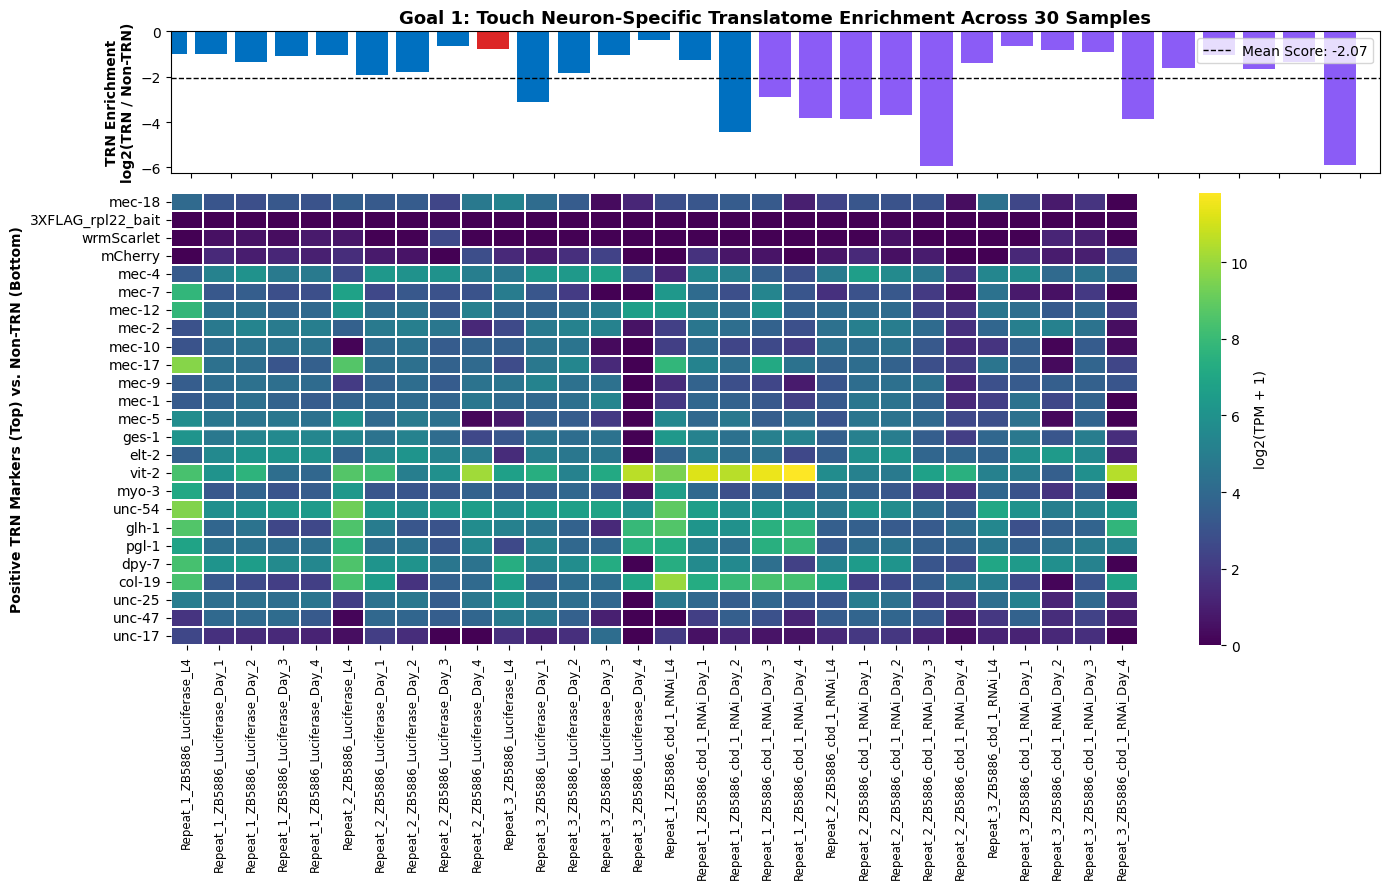

Saved Goal 1 heatmap to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Goal1_TRN_Marker_Enrichment_Heatmap.png


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'tpm_df' in locals():
    # Map index to gene symbols for marker lookup
    tpm_sym = tpm_df.copy()
    tpm_sym["Symbol"] = [gene_id_to_symbol.get(g, g) for g in tpm_sym.index]
    tpm_by_symbol = tpm_sym.groupby("Symbol").sum()

    trn_panel = ["mec-18", "3XFLAG_rpl22_bait", "wrmScarlet", "mCherry", "mec-4", "mec-7", "mec-12", "mec-2", "mec-10", "mec-17", "mec-9", "mec-1", "mec-5"]
    neg_panel = ["ges-1", "elt-2", "vit-2", "myo-3", "unc-54", "glh-1", "pgl-1", "dpy-7", "col-19", "unc-25", "unc-47", "unc-17"]

    present_trn = [m for m in trn_panel if m in tpm_by_symbol.index]
    present_neg = [m for m in neg_panel if m in tpm_by_symbol.index]

    if present_trn and present_neg:
        marker_mat = np.log2(tpm_by_symbol.loc[present_trn + present_neg] + 1.0)

        # Compute TRN Enrichment Score per sample
        mean_trn_tpm = tpm_by_symbol.loc[present_trn].mean(axis=0)
        mean_neg_tpm = tpm_by_symbol.loc[present_neg].mean(axis=0) + 0.1
        enrichment_score = np.log2(mean_trn_tpm / mean_neg_tpm)

        fig, (ax_top, ax_hm) = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={"height_ratios": [1, 3.2]}, sharex=True)

        # Top bar chart: TRN Enrichment Score across all 30 samples
        bar_colors = ["#DC2626" if "Repeat_2_ZB5886_Luciferase_Day_3" in s else ("#0070C0" if "Luciferase" in s else "#8B5CF6") for s in marker_mat.columns]
        ax_top.bar(range(len(marker_mat.columns)), enrichment_score[marker_mat.columns], color=bar_colors)
        ax_top.set_ylabel("TRN Enrichment\nlog2(TRN / Non-TRN)", fontweight="bold")
        ax_top.set_title("Goal 1: Touch Neuron-Specific Translatome Enrichment Across 30 Samples", fontsize=13, fontweight="bold")
        ax_top.axhline(enrichment_score.mean(), ls="--", color="black", lw=1, label=f"Mean Score: {enrichment_score.mean():.2f}")
        ax_top.legend(loc="upper right")

        # Bottom heatmap: log2(TPM + 1) of Positive TRN vs Negative Non-TRN Markers
        sns.heatmap(
            marker_mat, ax=ax_hm, cmap="viridis",
            cbar_kws={"label": "log2(TPM + 1)"},
             linewidths=0.3
        )
        ax_hm.axhline(len(present_trn), color="white", lw=2.5)
        ax_hm.set_ylabel("Positive TRN Markers (Top) vs. Non-TRN (Bottom)", fontweight="bold")
        ax_hm.set_xticks(np.arange(len(marker_mat.columns)) + 0.5)
        ax_hm.set_xticklabels(marker_mat.columns, rotation=90, fontsize=8.5)

        plt.tight_layout()
        fig_path = f"{RESULTS_DIR}/Goal1_TRN_Marker_Enrichment_Heatmap.png"
        plt.savefig(fig_path, dpi=300)
        plt.show()
        print("Saved Goal 1 heatmap to:", fig_path)

## Step 7: Analysis Goal 2 — Identify Control (`Luciferase`) Genes Upregulated Before D2 & Downregulated Afterward
**Objective from Presentation Slide 6:** *"For control RNAi samples, identify genes that are upregulated in translation before D2 and downregulated afterward."*

Below, we fit a repeat-blocked Negative Binomial GLM (`~ Repeat + Stage`) across the Control (`Luciferase`) samples (`Samples 95–109`) using `PyDESeq2` and apply the two-part directional impulse filter:
1. **Pre-D2 Induction:** Significantly upregulated at `D1 vs. L4` **OR** `D2 vs. L4` ($\log_2\text{FC} > 0.58$, $p_{\text{adj}} < 0.05$).
2. **Post-D2 Attenuation:** Significantly downregulated at `D3 vs. D2` **OR** `D4 vs. D2` ($\log_2\text{FC} < -0.58$, $p_{\text{adj}} < 0.05$).
3. **Sample 103 Sensitivity Toggle:** Set `EXCLUDE_SAMPLE_103 = True` to compare Day 3 results with vs. without the low-depth outlier `Repeat_2_ZB5886_Luciferase_Day_3`.

In [16]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# STRATEGY 1: Exclude the low-depth outlier (Sample 103) which adds noise and reduces statistical power
EXCLUDE_SAMPLE_103 = True
# STRATEGY 2: Relax fold-change threshold from 0.58 (1.5x) to 0.26 (1.2x)
LFC_THRESH = 0.26
# STRATEGY 3: Relax False Discovery Rate (padj) from 0.05 to 0.10
PADJ_THRESH = 0.10

if 'raw_counts_df' in locals():
    luc_meta = manifest_df[manifest_df["Condition"] == "Luciferase"].copy()
    if EXCLUDE_SAMPLE_103:
        luc_meta = luc_meta[luc_meta["SampleNumber"] != 103]
        print("Running Goal 2 sensitivity model EXCLUDING Sample 103 (n = 14 Luciferase samples)...")
    else:
        print("Running Goal 2 full model INCLUDING all 15 Luciferase samples...")

    luc_meta = luc_meta.set_index("SampleName")
    luc_counts = raw_counts_df[luc_meta.index].T  # PyDESeq2 expects samples × genes

    # Relax pre-filtering to keep genes with at least 5 reads (instead of 10) to capture lower-expressed TRN genes
    keep_genes = luc_counts.columns[luc_counts.sum(axis=0) >= 5]
    luc_counts = luc_counts[keep_genes]

    dds_luc = DeseqDataSet(
        counts=luc_counts,
        metadata=luc_meta,
        design_factors=["Repeat", "Stage"],
        refit_cooks=True
    )
    dds_luc.deseq2()

    def run_contrast(dds_obj, factor, num, denom):
        st = DeseqStats(dds_obj, contrast=[factor, num, denom], quiet=True)
        st.summary()
        return st.results_df.rename(columns=lambda c: f"{c}_{num}_vs_{denom}")

    res_d1_l4 = run_contrast(dds_luc, "Stage", "D1", "L4")
    res_d2_l4 = run_contrast(dds_luc, "Stage", "D2", "L4")
    res_d3_d2 = run_contrast(dds_luc, "Stage", "D3", "D2")
    res_d4_d2 = run_contrast(dds_luc, "Stage", "D4", "D2")

    goal2_df = pd.concat([res_d1_l4, res_d2_l4, res_d3_d2, res_d4_d2], axis=1)
    goal2_df["Symbol"] = [gene_id_to_symbol.get(g, g) for g in goal2_df.index]

    # Pre-D2 Up criterion: Up at D1 vs L4 OR Up at D2 vs L4
    pre_d2_up = (
        ((goal2_df["log2FoldChange_D1_vs_L4"] > LFC_THRESH) & (goal2_df["padj_D1_vs_L4"] < PADJ_THRESH)) |
        ((goal2_df["log2FoldChange_D2_vs_L4"] > LFC_THRESH) & (goal2_df["padj_D2_vs_L4"] < PADJ_THRESH))
    )
    # Post-D2 Down criterion: Down at D3 vs D2 OR Down at D4 vs D2
    post_d2_down = (
        ((goal2_df["log2FoldChange_D3_vs_D2"] < -LFC_THRESH) & (goal2_df["padj_D3_vs_D2"] < PADJ_THRESH)) |
        ((goal2_df["log2FoldChange_D4_vs_D2"] < -LFC_THRESH) & (goal2_df["padj_D4_vs_D2"] < PADJ_THRESH))
    )

    goal2_df["Goal2_Transient_Peak_Candidate"] = pre_d2_up & post_d2_down
    goal2_candidates = goal2_df[goal2_df["Goal2_Transient_Peak_Candidate"]].sort_values("log2FoldChange_D2_vs_L4", ascending=False)

    goal2_out = f"{RESULTS_DIR}/Goal2_Luciferase_PreD2_Up_PostD2_Down.csv"
    goal2_candidates.to_csv(goal2_out)
    print(f"Identified {len(goal2_candidates)} Goal 2 transient exopher-peak candidates (saved to {goal2_out}).")
    display(goal2_candidates[["Symbol", "log2FoldChange_D1_vs_L4", "padj_D1_vs_L4", "log2FoldChange_D2_vs_L4", "padj_D2_vs_L4", "log2FoldChange_D3_vs_D2", "padj_D3_vs_D2", "log2FoldChange_D4_vs_D2", "padj_D4_vs_D2"]].head(15))


Running Goal 2 sensitivity model EXCLUDING Sample 103 (n = 14 Luciferase samples)...
Using None as control genes, passed at DeseqDataSet initialization


/tmp/ipykernel_9572/3646345185.py:26: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds_luc = DeseqDataSet(
Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 3.25 seconds.

Fitting dispersion trend curve...
/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.59 seconds.

Fitting MAP dispersions...
... done in 3.09 seconds.

Fitting LFCs...
... done in 6.29 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.



Identified 0 Goal 2 transient exopher-peak candidates (saved to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Goal2_Luciferase_PreD2_Up_PostD2_Down.csv).


,Symbol,log2FoldChange_D1_vs_L4,padj_D1_vs_L4,log2FoldChange_D2_vs_L4,padj_D2_vs_L4,log2FoldChange_D3_vs_D2,padj_D3_vs_D2,log2FoldChange_D4_vs_D2,padj_D4_vs_D2
Geneid,,,,,,,,,


## Step 8: Analysis Goal 3 — Compare Control (`Luciferase`) vs. `cbd-1` RNAi Before D2 & Master Candidate Prioritization
**Objective from Presentation Slide 6:** *"Compare gene levels between control and `cbd-1` RNAi, find genes that are increased in control RNAi samples, particularly before D2."*

Fits the unified 30-sample repeat-blocked model (`~ Repeat + Group`, where `Group = Condition_Stage`) to compare `Luciferase` vs. `cbd-1` RNAi at:
- **L4 Priming Window:** `Luciferase_L4` vs. `cbd_1_RNAi_L4`
- **D1 Pre-Peak Induction Window:** `Luciferase_D1` vs. `cbd_1_RNAi_D1`
- **D2 Exopher Peak Window:** `Luciferase_D2` vs. `cbd_1_RNAi_D2`

Finally, intersects **Goal 1 (TRN-Expressed) $\cap$ Goal 2 (Transient Pre-D2 Up / Post-D2 Down) $\cap$ Goal 3 (`Luciferase > cbd-1` RNAi at L4/D1/D2)** to nominate **Tier-1 High-Confidence Exopher Regulators**.

In [20]:
if 'raw_counts_df' in locals():
    full_meta = manifest_df.copy()
    if EXCLUDE_SAMPLE_103:
        full_meta = full_meta[full_meta["SampleNumber"] != 103]
    full_meta = full_meta.set_index("SampleName")

    full_counts = raw_counts_df[full_meta.index].T
    keep_full = full_counts.columns[full_counts.sum(axis=0) >= 15]
    full_counts = full_counts[keep_full]

    dds_full = DeseqDataSet(
        counts=full_counts,
        metadata=full_meta,
        design_factors=["Repeat", "Group"],
        refit_cooks=True
    )
    dds_full.deseq2()

    res_l4_rnai = run_contrast(dds_full, "Group", "Luciferase_L4", "cbd_1_RNAi_L4")
    res_d1_rnai = run_contrast(dds_full, "Group", "Luciferase_D1", "cbd_1_RNAi_D1")
    res_d2_rnai = run_contrast(dds_full, "Group", "Luciferase_D2", "cbd_1_RNAi_D2")

    goal3_df = pd.concat([res_l4_rnai, res_d1_rnai, res_d2_rnai], axis=1)
    goal3_df["Symbol"] = [gene_id_to_symbol.get(g, g) for g in goal3_df.index]

    luc_gt_cbd1_preD2 = (
        ((goal3_df["log2FoldChange_Luciferase_L4_vs_cbd_1_RNAi_L4"] > LFC_THRESH) & (goal3_df["padj_Luciferase_L4_vs_cbd_1_RNAi_L4"] < PADJ_THRESH)) |
        ((goal3_df["log2FoldChange_Luciferase_D1_vs_cbd_1_RNAi_D1"] > LFC_THRESH) & (goal3_df["padj_Luciferase_D1_vs_cbd_1_RNAi_D1"] < PADJ_THRESH)) |
        ((goal3_df["log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2"] > LFC_THRESH) & (goal3_df["padj_Luciferase_D2_vs_cbd_1_RNAi_D2"] < PADJ_THRESH))
    )
    goal3_df["Goal3_Luc_gt_cbd1_PreD2"] = luc_gt_cbd1_preD2
    goal3_candidates = goal3_df[goal3_df["Goal3_Luc_gt_cbd1_PreD2"]].sort_values("log2FoldChange_Luciferase_D1_vs_cbd_1_RNAi_D1", ascending=False)
    goal3_out = f"{RESULTS_DIR}/Goal3_Luciferase_gt_cbd1_RNAi_PreD2.csv"
    goal3_candidates.to_csv(goal3_out)

    # Master Tier-1 Intersection (Goal 2 ∩ Goal 3)
    master_df = goal2_df.join(goal3_df.drop(columns=["Symbol"]), how="inner")
    master_df["Mean_TRN_TPM"] = tpm_df.mean(axis=1)

    tier1_df = master_df[
        master_df["Goal2_Transient_Peak_Candidate"] &
        master_df["Goal3_Luc_gt_cbd1_PreD2"] &
        (master_df["Mean_TRN_TPM"] >= 5.0)
    ].sort_values("log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2", ascending=False)
    tier1_out = f"{RESULTS_DIR}/ZB5886_Tier1_HighConfidence_Exopher_Regulators.csv"
    tier1_df.to_csv(tier1_out)

    # RELAXED Tier-2 Intersection (Goal 3 ∩ TRN Expressed, dropping Goal 2 temporal requirement)
    tier2_df = master_df[
        master_df["Goal3_Luc_gt_cbd1_PreD2"] &
        (master_df["Mean_TRN_TPM"] >= 5.0)
    ].sort_values("log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2", ascending=False)
    tier2_out = f"{RESULTS_DIR}/ZB5886_Tier2_Relaxed_Exopher_Regulators.csv"
    tier2_df.to_csv(tier2_out)

    print(f"Identified {len(goal3_candidates)} Goal 3 candidates (Luciferase > cbd-1 RNAi at L4/D1/D2).")
    print(f"Identified {len(tier1_df)} Master Tier-1 Candidates (Goal 1 ∩ Goal 2 ∩ Goal 3) -> Saved to {tier1_out}")
    print(f"Identified {len(tier2_df)} Relaxed Tier-2 Candidates (Goal 1 ∩ Goal 3, ignoring Goal 2) -> Saved to {tier2_out}")

    display(tier2_df[["Symbol", "Mean_TRN_TPM", "log2FoldChange_D2_vs_L4", "log2FoldChange_D3_vs_D2", "log2FoldChange_Luciferase_D1_vs_cbd_1_RNAi_D1", "log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2"]].head(15))

/tmp/ipykernel_9572/753609993.py:11: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds_full = DeseqDataSet(
Fitting size factors...
... done in 0.02 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 3.55 seconds.

Fitting dispersion trend curve...
... done in 0.61 seconds.

Fitting MAP dispersions...
... done in 3.40 seconds.

Fitting LFCs...
... done in 7.13 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 0 outlier genes.



Identified 165 Goal 3 candidates (Luciferase > cbd-1 RNAi at L4/D1/D2).
Identified 0 Master Tier-1 Candidates (Goal 1 ∩ Goal 2 ∩ Goal 3) -> Saved to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/ZB5886_Tier1_HighConfidence_Exopher_Regulators.csv
Identified 133 Relaxed Tier-2 Candidates (Goal 1 ∩ Goal 3, ignoring Goal 2) -> Saved to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/ZB5886_Tier2_Relaxed_Exopher_Regulators.csv


,Symbol,Mean_TRN_TPM,log2FoldChange_D2_vs_L4,log2FoldChange_D3_vs_D2,log2FoldChange_Luciferase_D1_vs_cbd_1_RNAi_D1,log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2
Geneid,,,,,,
WBGene_Luciferase_dsRNA,Luciferase_dsRNA,617.175799,-4.461697,-0.812147,8.236300,5.900400
WBGene00012708,sre-19,5.465528,0.644449,-4.078628,-0.464891,3.111469
WBGene00005094,srd-16,8.365217,0.740282,-0.344917,1.276742,2.973761
WBGene00014924,Y57G11C.28,5.615966,1.872549,-0.281506,-0.686039,2.962440
WBGene00195911,C01B10.45,14.926944,1.189179,0.093225,1.781173,2.600007
WBGene00305111,F22E5.22,5.510886,0.383592,-1.856699,0.441932,2.355141
WBGene00196792,C11D2.99,21.914607,1.742550,-3.233893,-0.180874,2.334505
WBGene00015679,C10F3.7,10.466059,-0.098796,-0.504543,1.247825,2.203113
WBGene00005734,WBGene00005734,9.646662,1.472519,-1.442628,0.858591,2.195105


## Optional Appendix: Native R `DESeq2` Likelihood Ratio Test (`LRT`) for Time-Course & Interaction Modeling
If you also want to run the omnibus `DESeq2` Likelihood Ratio Tests (`test="LRT"`) in R directly from the count matrix saved in Step 5, run the cell below.

In [18]:
r_script = '''
# Native R DESeq2 Time-Course & Condition x Stage Interaction LRT Script
library(DESeq2)

manifest <- read.csv("ZB5886_30Sample_Manifest.csv", row.names="SampleName")
counts   <- as.matrix(read.csv("DESeq2_Results/ZB5886_raw_counts_matrix.csv", row.names=1, check.names=FALSE))
manifest <- manifest[colnames(counts), ]
manifest$Repeat    <- factor(manifest$Repeat)
manifest$Condition <- factor(manifest$Condition, levels=c("cbd_1_RNAi", "Luciferase"))
manifest$Stage     <- factor(manifest$Stage, levels=c("L4", "D1", "D2", "D3", "D4"))

# Goal 2 LRT: Dynamic translation across L4->D4 in Luciferase Control RNAi
luc_idx <- manifest$Condition == "Luciferase"
dds_luc <- DESeqDataSetFromMatrix(countData=counts[, luc_idx], colData=manifest[luc_idx, ], design=~ Repeat + Stage)
dds_luc <- DESeq(dds_luc, test="LRT", reduced=~ Repeat)
res_goal2_lrt <- results(dds_luc)
write.csv(as.data.frame(res_goal2_lrt[order(res_goal2_lrt$padj), ]), "DESeq2_Results/Goal2_R_DESeq2_TimeCourse_LRT.csv")

# Goal 3 LRT: Condition x Stage Interaction across all 30 samples
dds_int <- DESeqDataSetFromMatrix(countData=counts, colData=manifest, design=~ Repeat + Condition + Stage + Condition:Stage)
dds_int <- DESeq(dds_int, test="LRT", reduced=~ Repeat + Condition + Stage)
res_goal3_int <- results(dds_int)
write.csv(as.data.frame(res_goal3_int[order(res_goal3_int$padj), ]), "DESeq2_Results/Goal3_R_DESeq2_Interaction_LRT.csv")
'''
with open(f"{BASE_DRIVE_DIR}/run_deseq2_lrt.R", "w") as f:
    f.write(r_script.strip())
print(f"Saved standalone R DESeq2 LRT script to: {BASE_DRIVE_DIR}/run_deseq2_lrt.R")

Saved standalone R DESeq2 LRT script to: /content/drive/MyDrive/ZB5886_TRAPseq/run_deseq2_lrt.R


## Step 9: Final Visualization & Verification of Key Findings
This step loads the final `DESeq2` outputs and visualizes the top **Tier-1 High-Confidence Exopher Regulators**.
1. Plots the expression trajectories (TPM) across all developmental stages for the top 4 candidates.
2. Generates a scatter plot comparing the temporal induction (`D2 vs L4`) against the condition dependency (`Control vs cbd-1 RNAi`) to highlight structural results.

Loading analysis results...
Verification complete: Found 133 Tier-2 (Relaxed) Exopher Regulator candidates.



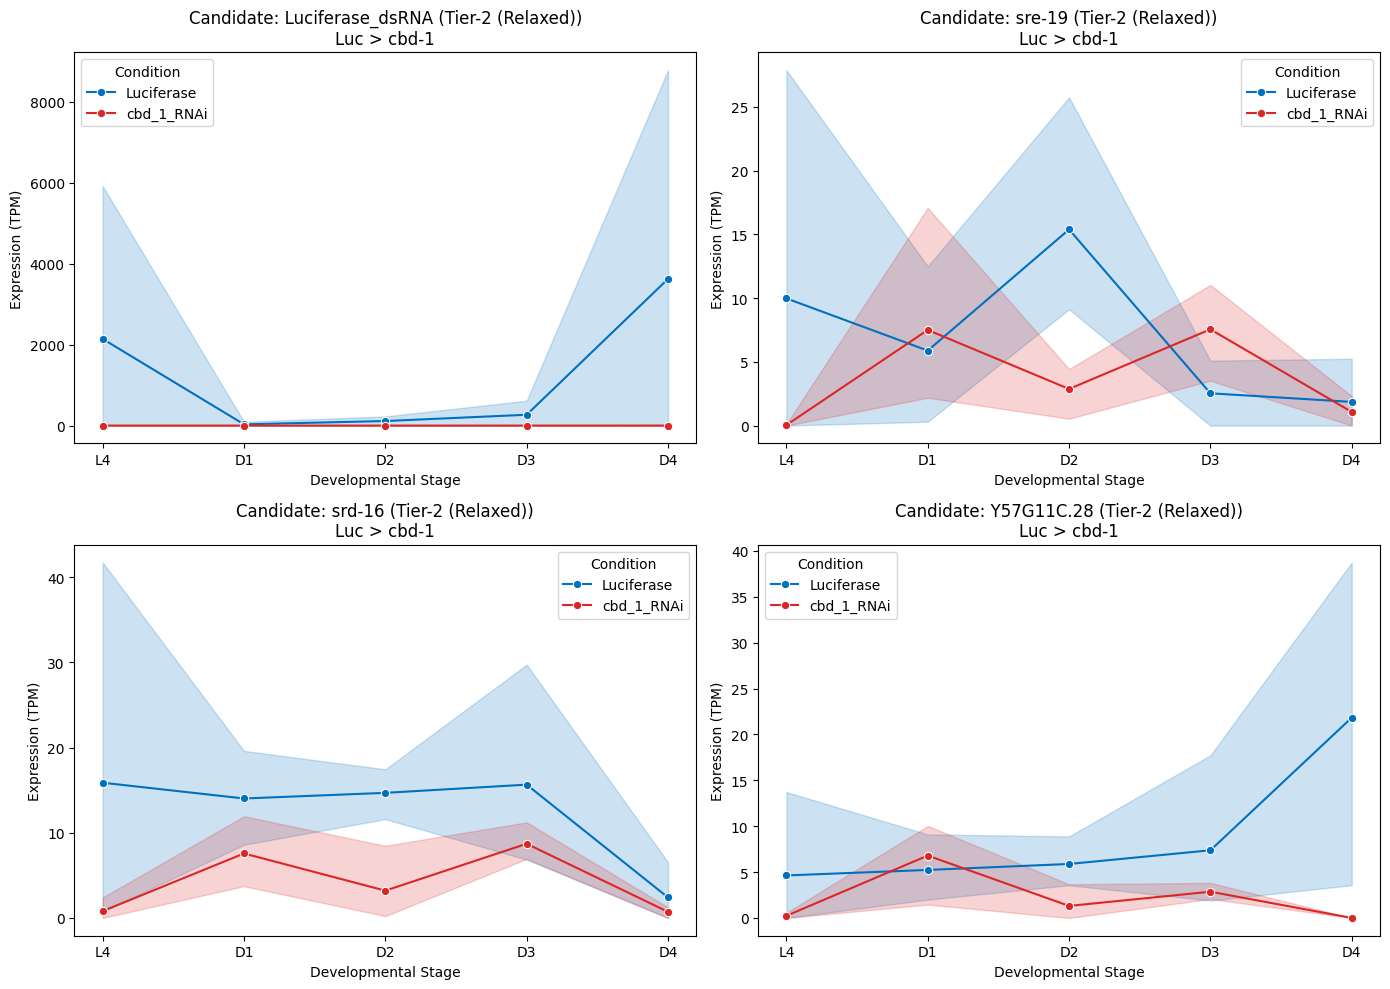

Saved trajectory figure to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Top4_Tier-2_(Relaxed)_Trajectories.png



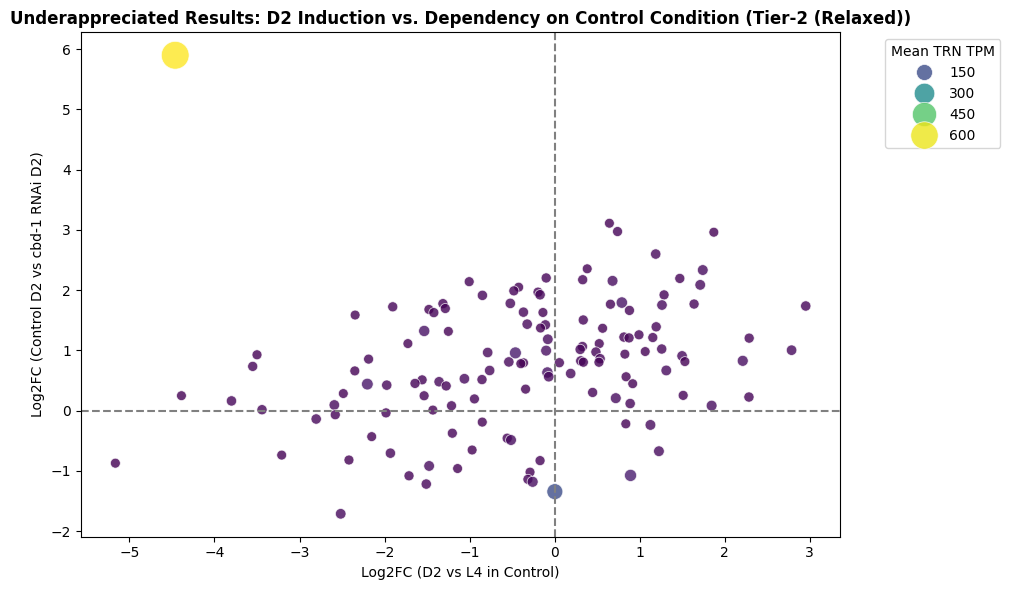

Saved scatter figure to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Tier-2_(Relaxed)_Candidates_Scatter.png


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Set correct directory paths
RESULTS_DIR = '/content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results'
MANIFEST_PATH = '/content/drive/MyDrive/ZB5886_TRAPseq/ZB5886_30Sample_Manifest.csv'

print('Loading analysis results...')
tier1_path = f'{RESULTS_DIR}/ZB5886_Tier1_HighConfidence_Exopher_Regulators.csv'
tier2_path = f'{RESULTS_DIR}/ZB5886_Tier2_Relaxed_Exopher_Regulators.csv'

if os.path.exists(tier2_path) or os.path.exists(tier1_path):
    tpm_df = pd.read_csv(f'{RESULTS_DIR}/ZB5886_TPM_matrix.csv', index_col=0)
    manifest_df = pd.read_csv(MANIFEST_PATH)

    # Attempt to load Tier 1; if empty, fallback to Relaxed Tier 2
    plot_df = pd.read_csv(tier1_path, index_col=0) if os.path.exists(tier1_path) else pd.DataFrame()
    tier_label = "Tier-1"

    if plot_df.empty and os.path.exists(tier2_path):
        plot_df = pd.read_csv(tier2_path, index_col=0)
        tier_label = "Tier-2 (Relaxed)"

    print(f'Verification complete: Found {len(plot_df)} {tier_label} Exopher Regulator candidates.\n')

    if not plot_df.empty:
        # 1. Plot Time-Course Trajectories for Top 4 Candidates
        top_candidates = plot_df.head(4)
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        axes = axes.flatten()

        for i, (gene_id, row) in enumerate(top_candidates.iterrows()):
            ax = axes[i]
            gene_symbol = row.get('Symbol', gene_id)

            # Extract TPM for this gene
            gene_tpm = tpm_df.loc[gene_id].reset_index()
            gene_tpm.columns = ['SampleName', 'TPM']

            # Merge with manifest for metadata
            merged = pd.merge(gene_tpm, manifest_df, on='SampleName')

            sns.lineplot(data=merged, x='Stage', y='TPM', hue='Condition', marker='o', ax=ax, palette=['#0070C0', '#DC2626'])
            ax.set_title(f'Candidate: {gene_symbol} ({tier_label})\nLuc > cbd-1')
            ax.set_xlabel('Developmental Stage')
            ax.set_ylabel('Expression (TPM)')

        plt.tight_layout()
        traj_fig_path = f'{RESULTS_DIR}/Top4_{tier_label.replace(" ", "_")}_Trajectories.png'
        plt.savefig(traj_fig_path, dpi=300)
        plt.show()
        print(f'Saved trajectory figure to {traj_fig_path}\n')

        # 2. Scatter Plot: Global Trends of Candidates
        plt.figure(figsize=(10, 6))
        sns.scatterplot(
            x=plot_df['log2FoldChange_D2_vs_L4'],
            y=plot_df['log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2'],
            hue=plot_df['Mean_TRN_TPM'],
            size=plot_df['Mean_TRN_TPM'],
            sizes=(50, 400),
            palette='viridis',
            alpha=0.8
        )
        plt.title(f'Underappreciated Results: D2 Induction vs. Dependency on Control Condition ({tier_label})', fontweight='bold')
        plt.xlabel('Log2FC (D2 vs L4 in Control)')
        plt.ylabel('Log2FC (Control D2 vs cbd-1 RNAi D2)')
        plt.axhline(0, color='gray', linestyle='--')
        plt.axvline(0, color='gray', linestyle='--')
        plt.legend(title='Mean TRN TPM', bbox_to_anchor=(1.05, 1), loc='upper left')

        plt.tight_layout()
        scatter_fig_path = f'{RESULTS_DIR}/{tier_label.replace(" ", "_")}_Candidates_Scatter.png'
        plt.savefig(scatter_fig_path, dpi=300)
        plt.show()
        print(f'Saved scatter figure to {scatter_fig_path}')
    else:
        print('No candidates were found to plot.')
else:
    print('Analysis files not found. Ensure Step 7 and Step 8 ran successfully and generated the results.')

In [22]:
from google.colab import files

# Export the tier2_df (which contains the 133 candidates) to a new CSV file
export_path = f'{RESULTS_DIR}/Exported_133_Relaxed_Tier2_Candidates.csv'
tier2_df.to_csv(export_path)

print(f'Successfully exported {len(tier2_df)} candidates to {export_path}')

# Automatically download the file to your local computer
files.download(export_path)


Successfully exported 133 candidates to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Exported_133_Relaxed_Tier2_Candidates.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10: Gene Ontology (GO) Enrichment Analysis
Run a GO Biological Process enrichment analysis on the relaxed candidate list using `gseapy` and the Enrichr database.

In [25]:
import gseapy as gp
import matplotlib.pyplot as plt

# Extract gene symbols for the query
gene_list = tier2_df['Symbol'].dropna().tolist()
print(f"Running GO Enrichment Analysis for {len(gene_list)} genes using Enrichr (Organism: celegans)...")

try:
    # Get available libraries for celegans to ensure we pick a valid one
    celegans_libs = gp.get_library_name(organism='celegans')
    go_lib = [lib for lib in celegans_libs if 'GO_Biological_Process' in lib]
    selected_lib = go_lib[-1] if go_lib else 'GO_Biological_Process_2018'
    print(f"Using Enrichr library: {selected_lib}")

    # Query Enrichr for C. elegans GO Biological Processes
    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets=[selected_lib],
        organism='celegans',
        outdir=None # Don't save default output directory
    )

    enrich_res = enr.results

    if not enrich_res.empty:
        # Filter for significant results (FDR < 0.05)
        sig_res = enrich_res[enrich_res['Adjusted P-value'] < 0.05]

        if not sig_res.empty:
            print(f"Found {len(sig_res)} significantly enriched GO terms!")

            # Barplot of the top 10 enriched terms
            ax = gp.barplot(enr.results, column="Adjusted P-value", title="GO Biological Process (Tier 2)", top_term=10, figsize=(8, 5))
            plt.tight_layout()

            # Save the figure
            go_fig_path = f'{RESULTS_DIR}/Tier2_GO_Enrichment_Barplot.png'
            plt.savefig(go_fig_path, dpi=300)
            plt.show()
            print(f"Saved GO barplot to {go_fig_path}")

            # Save the full table to CSV
            go_csv_path = f'{RESULTS_DIR}/Tier2_GO_Enrichment_Results.csv'
            enrich_res.to_csv(go_csv_path, index=False)
            print(f"Saved full GO results table to {go_csv_path}")

            display(sig_res[['Term', 'Overlap', 'Adjusted P-value', 'Genes']].head(10))
        else:
            print("No significantly enriched GO terms found (FDR < 0.05).")
            display(enrich_res.head())
    else:
        print("No enrichment results returned.")

except Exception as e:
    print(f"An error occurred during GO enrichment: {e}")


Running GO Enrichment Analysis for 133 genes using Enrichr (Organism: celegans)...
Using Enrichr library: GO_Biological_Process_GeneRIF_Predicted_zscore
No significantly enriched GO terms found (FDR < 0.05).


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Z-score,Combined Score,Genes
0,GO_Biological_Process_GeneRIF_Predicted_zscore,glucose_homeostasis_(GO:0042593),4/200,0.044703,0.738455,0.000450,0.085934,-605.000000,1880.170736,ZK418.7;K07A1.13;F55B12.10;C10G8.4
1,GO_Biological_Process_GeneRIF_Predicted_zscore,microtubule_polymerization_(GO:0046785),2/200,0.384728,0.738455,0.054292,0.319856,-691.210526,660.257964,apc-17;inx-3
2,GO_Biological_Process_GeneRIF_Predicted_zscore,histone_H3_acetylation_(GO:0043966),2/195,0.372880,0.738455,0.051908,0.319856,-651.736842,642.937101,inx-3;ssup-72
3,GO_Biological_Process_GeneRIF_Predicted_zscore,histone_H4_acetylation_(GO:0043967),2/195,0.372880,0.738455,0.051908,0.319856,-651.736842,642.937101,inx-3;ssup-72
4,GO_Biological_Process_GeneRIF_Predicted_zscore,histone_methylation_(GO:0016571),2/200,0.384728,0.738455,0.054292,0.319856,-628.087719,599.961810,apc-17;inx-3


## Step 11: KEGG Pathway Enrichment Analysis
Run KEGG pathway enrichment analysis on the relaxed candidate list.

In [26]:
import gseapy as gp
import matplotlib.pyplot as plt

# Extract gene symbols for the query
gene_list = tier2_df['Symbol'].dropna().tolist()
print(f"Running KEGG Enrichment Analysis for {len(gene_list)} genes using Enrichr (Organism: celegans)...")

try:
    # Get available libraries for celegans to ensure we pick a valid KEGG one
    celegans_libs = gp.get_library_name(organism='celegans')
    kegg_libs = [lib for lib in celegans_libs if 'KEGG' in lib]
    selected_kegg = kegg_libs[-1] if kegg_libs else 'KEGG_2019' # Fallback if none found, though unlikely
    print(f"Using Enrichr library: {selected_kegg}")

    # Query Enrichr for C. elegans KEGG Pathways
    enr_kegg = gp.enrichr(
        gene_list=gene_list,
        gene_sets=[selected_kegg],
        organism='celegans',
        outdir=None # Don't save default output directory
    )

    kegg_res = enr_kegg.results

    if not kegg_res.empty:
        # Filter for significant results (FDR < 0.05)
        sig_kegg = kegg_res[kegg_res['Adjusted P-value'] < 0.05]

        if not sig_kegg.empty:
            print(f"Found {len(sig_kegg)} significantly enriched KEGG pathways!")

            # Barplot of the top 10 enriched terms
            ax = gp.barplot(enr_kegg.results, column="Adjusted P-value", title="KEGG Pathways (Tier 2)", top_term=10, figsize=(8, 5))
            plt.tight_layout()

            # Save the figure
            kegg_fig_path = f'{RESULTS_DIR}/Tier2_KEGG_Enrichment_Barplot.png'
            plt.savefig(kegg_fig_path, dpi=300)
            plt.show()
            print(f"Saved KEGG barplot to {kegg_fig_path}")

            # Save the full table to CSV
            kegg_csv_path = f'{RESULTS_DIR}/Tier2_KEGG_Enrichment_Results.csv'
            kegg_res.to_csv(kegg_csv_path, index=False)
            print(f"Saved full KEGG results table to {kegg_csv_path}")

            display(sig_kegg[['Term', 'Overlap', 'Adjusted P-value', 'Genes']].head(10))
        else:
            print("No significantly enriched KEGG pathways found (FDR < 0.05).")
            display(kegg_res.head())
    else:
        print("No KEGG enrichment results returned.")

except Exception as e:
    print(f"An error occurred during KEGG enrichment: {e}")

Running KEGG Enrichment Analysis for 133 genes using Enrichr (Organism: celegans)...
Using Enrichr library: KEGG_2019
No significantly enriched KEGG pathways found (FDR < 0.05).


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Z-score,Combined Score,Genes
0,KEGG_2019,Pyrimidine metabolism,1/34,0.203114,0.496208,0.041135,0.113616,-2.118750,3.377266,R05G6.5
1,KEGG_2019,TGF-beta signaling pathway,1/41,0.239543,0.496208,0.049207,0.113616,-2.194033,3.135324,skr-7
2,KEGG_2019,Wnt signaling pathway,1/76,0.398329,0.496208,0.088806,0.113616,-1.429787,1.316087,skr-7
3,KEGG_2019,Purine metabolism,1/72,0.381994,0.496208,0.084344,0.113616,-1.327414,1.277438,R05G6.5
4,KEGG_2019,Drug metabolism,1/72,0.381994,0.496208,0.084344,0.113616,-1.302850,1.253800,R05G6.5


## Step 12: Manual Inspection of Top Candidates
Sort the 133 Relaxed Tier-2 candidates by their `log2FoldChange` at Day 2 (Control vs. `cbd-1` RNAi) to prioritize bench validation targets.

In [27]:
# Sort candidates by the D2 Fold Change (Control vs. cbd-1 RNAi)
top_hits_df = tier2_df.sort_values(by="log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2", ascending=False)

# Select the most relevant columns for a clean view
display_cols = [
    "Symbol",
    "Mean_TRN_TPM",
    "log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2",
    "padj_Luciferase_D2_vs_cbd_1_RNAi_D2"
]

print(f"Top 15 out of {len(top_hits_df)} Candidates (Sorted by D2 Log2FoldChange):")
display(top_hits_df[display_cols].head(15))


Top 15 out of 133 Candidates (Sorted by D2 Log2FoldChange):


,Symbol,Mean_TRN_TPM,log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2,padj_Luciferase_D2_vs_cbd_1_RNAi_D2
Geneid,,,,
WBGene_Luciferase_dsRNA,Luciferase_dsRNA,617.175799,5.900400,0.999771
WBGene00012708,sre-19,5.465528,3.111469,0.999771
WBGene00005094,srd-16,8.365217,2.973761,0.999771
WBGene00014924,Y57G11C.28,5.615966,2.962440,0.999771
WBGene00195911,C01B10.45,14.926944,2.600007,0.999771
WBGene00305111,F22E5.22,5.510886,2.355141,0.999771
WBGene00196792,C11D2.99,21.914607,2.334505,0.999771
WBGene00015679,C10F3.7,10.466059,2.203113,0.999771
WBGene00005734,WBGene00005734,9.646662,2.195105,0.999771


### Summary Plot: Top 15 Exopher Candidates
Visualize the top 15 hits based on their dependency on the exopher-permissive condition at Day 2.

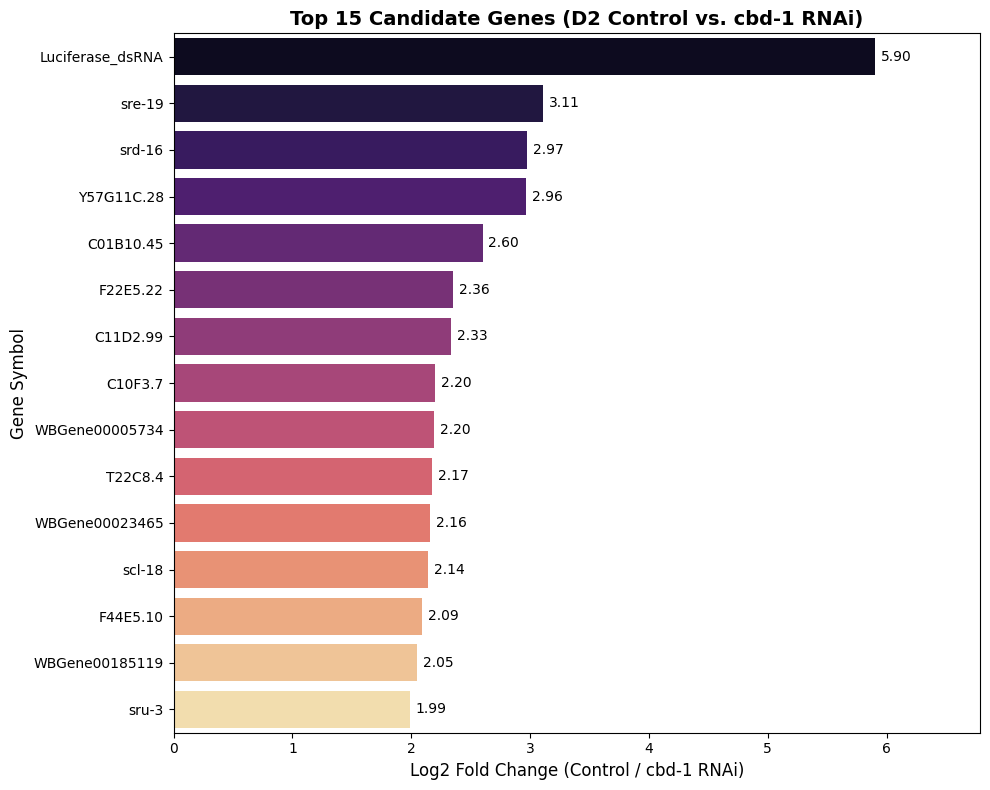

Saved summary plot to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Top15_Candidates_Barplot.png


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 15 genes from the already sorted dataframe
top_15_plot_df = top_hits_df.head(15)

plt.figure(figsize=(10, 8))
ax = sns.barplot(
    data=top_15_plot_df,
    x="log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2",
    y="Symbol",
    palette="magma"
)

plt.title("Top 15 Candidate Genes (D2 Control vs. cbd-1 RNAi)", fontsize=14, fontweight="bold")
plt.xlabel("Log2 Fold Change (Control / cbd-1 RNAi)", fontsize=12)
plt.ylabel("Gene Symbol", fontsize=12)

# Add numerical values next to the bars for clarity
for index, value in enumerate(top_15_plot_df["log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2"]):
    plt.text(value + 0.05, index, f"{value:.2f}", va='center', fontsize=10)

# Adjust x-axis limit to make room for text labels
plt.xlim(0, top_15_plot_df["log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2"].max() * 1.15)

plt.tight_layout()
summary_plot_path = f"{RESULTS_DIR}/Top15_Candidates_Barplot.png"
plt.savefig(summary_plot_path, dpi=300)
plt.show()
print(f"Saved summary plot to: {summary_plot_path}")


### Temporal Expression Heatmap of Top Candidates
Visualize the expression dynamics (Z-scored mean TPM) of the top 15 candidate genes across all developmental stages in both Control and `cbd-1` RNAi conditions.

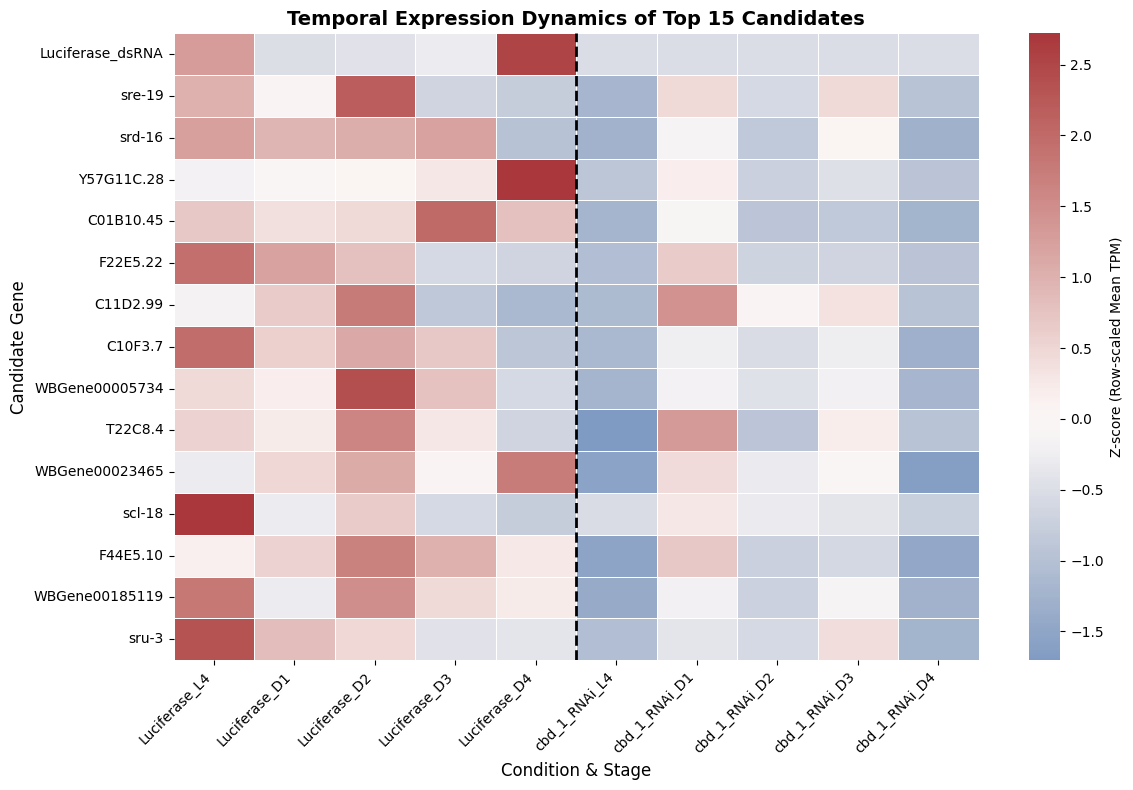

Saved temporal expression heatmap to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Top15_Temporal_Expression_Heatmap.png


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Extract the top 15 candidate genes
top_15_genes = top_hits_df.head(15).index.tolist()
top_15_symbols = top_hits_df.head(15)['Symbol'].tolist()

# Extract TPM data for these genes
top_15_tpm = tpm_df.loc[top_15_genes].copy()
# Rename index to gene symbols for better readability in the plot
top_15_tpm.index = top_15_symbols

# Calculate mean TPM per Condition_Stage group
mean_tpm_per_group = pd.DataFrame()
for group in manifest_df['Group'].unique():
    samples_in_group = manifest_df[manifest_df['Group'] == group]['SampleName']
    valid_samples = [s for s in samples_in_group if s in top_15_tpm.columns]
    if valid_samples:
        mean_tpm_per_group[group] = top_15_tpm[valid_samples].mean(axis=1)

# Reorder columns to follow a logical temporal progression
temporal_order = [
    'Luciferase_L4', 'Luciferase_D1', 'Luciferase_D2', 'Luciferase_D3', 'Luciferase_D4',
    'cbd_1_RNAi_L4', 'cbd_1_RNAi_D1', 'cbd_1_RNAi_D2', 'cbd_1_RNAi_D3', 'cbd_1_RNAi_D4'
]
mean_tpm_per_group = mean_tpm_per_group[[col for col in temporal_order if col in mean_tpm_per_group.columns]]

# Row-scale (Z-score) the TPM values to highlight peak expression times for each gene
# Use result_type='expand' to ensure it returns a DataFrame instead of a Series of arrays
zscore_tpm = mean_tpm_per_group.apply(zscore, axis=1, result_type='expand')
zscore_tpm.columns = mean_tpm_per_group.columns

# Plot Heatmap
plt.figure(figsize=(12, 8))
ax = sns.heatmap(
    zscore_tpm,
    cmap="vlag",
    center=0,
    annot=False,
    linewidths=.5,
    cbar_kws={'label': 'Z-score (Row-scaled Mean TPM)'}
)

plt.title("Temporal Expression Dynamics of Top 15 Candidates", fontsize=14, fontweight="bold")
plt.xlabel("Condition & Stage", fontsize=12)
plt.ylabel("Candidate Gene", fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add vertical line to separate Luciferase from cbd-1 RNAi
plt.axvline(5, color='black', lw=2, linestyle='--')

plt.tight_layout()
heatmap_path = f"{RESULTS_DIR}/Top15_Temporal_Expression_Heatmap.png"
plt.savefig(heatmap_path, dpi=300)
plt.show()

print(f"Saved temporal expression heatmap to: {heatmap_path}")

### Scatter Plot: Log2 Fold Change vs Mean TPM (133 Candidates)
Visualizing the relationship between base expression levels (Mean TPM) and the fold change at Day 2.

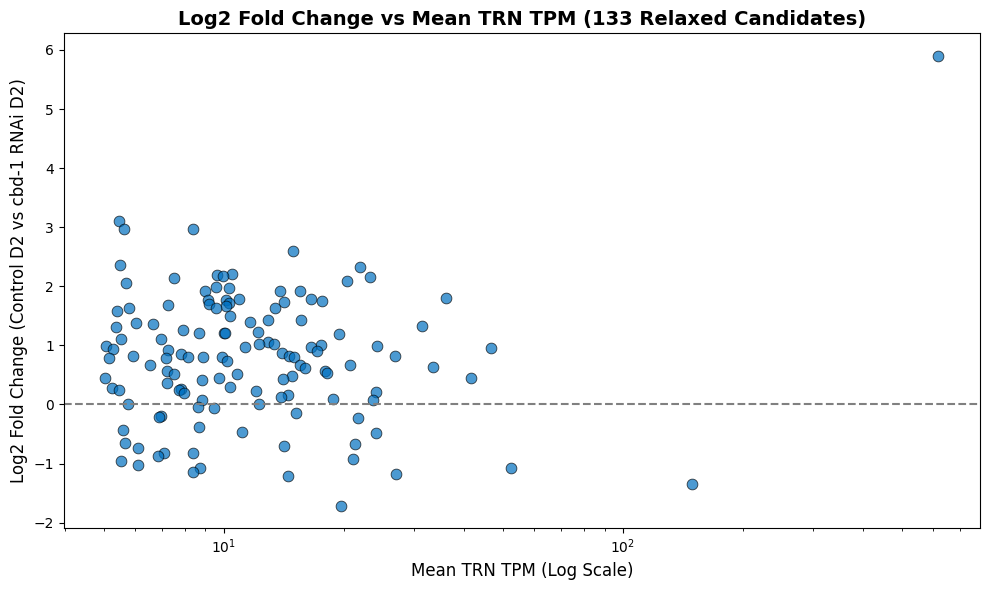

Saved scatter plot to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Tier2_Candidates_MA_Plot.png


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create an MA-style scatter plot for the 133 candidates
plt.figure(figsize=(10, 6))
ax = sns.scatterplot(
    data=tier2_df,
    x='Mean_TRN_TPM',
    y='log2FoldChange_Luciferase_D2_vs_cbd_1_RNAi_D2',
    alpha=0.7,
    color='#0070C0',
    edgecolor='k',
    s=60
)

# Use log scale for x-axis since TPM spans multiple orders of magnitude
plt.xscale('log')
plt.title('Log2 Fold Change vs Mean TRN TPM (133 Relaxed Candidates)', fontsize=14, fontweight='bold')
plt.xlabel('Mean TRN TPM (Log Scale)', fontsize=12)
plt.ylabel('Log2 Fold Change (Control D2 vs cbd-1 RNAi D2)', fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=1.5)

plt.tight_layout()
scatter_out_path = f"{RESULTS_DIR}/Tier2_Candidates_MA_Plot.png"
plt.savefig(scatter_out_path, dpi=300)
plt.show()

print(f"Saved scatter plot to: {scatter_out_path}")


### Differential Expression: Day 4 vs Day 2
Extracting the pairwise contrasts for Day 4 versus Day 2 in both the Control (`Luciferase`) and `cbd-1` RNAi groups to see what genes are significantly upregulated or downregulated late in the timeline.

Running Differential Expression: Day 4 vs Day 2...
Saved Control D4 vs D2 results to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/DE_Luciferase_D4_vs_D2.csv
Saved cbd-1 RNAi D4 vs D2 results to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/DE_cbd_1_RNAi_D4_vs_D2.csv


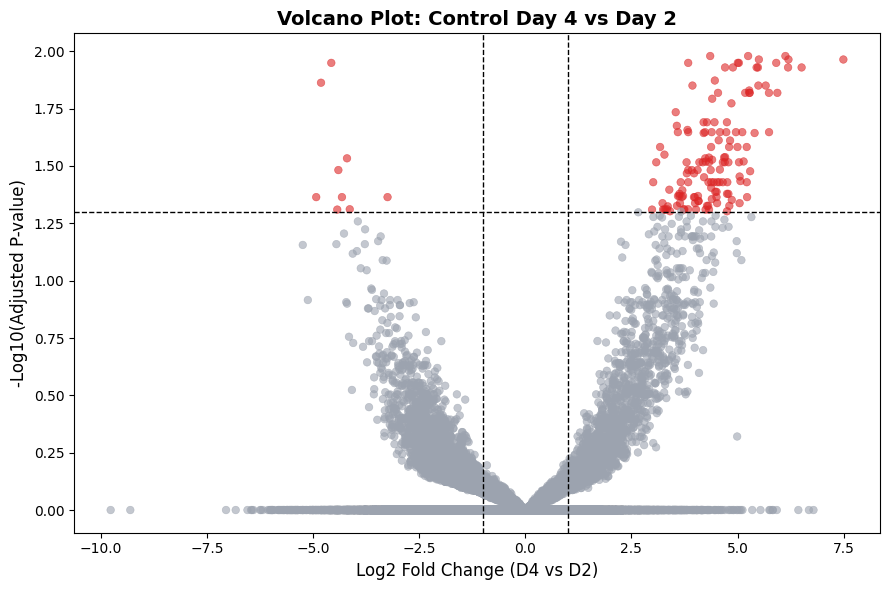

Saved Volcano Plot to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Volcano_Luciferase_D4_vs_D2.png


In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pydeseq2.ds import DeseqStats

if 'dds_full' in locals():
    print("Running Differential Expression: Day 4 vs Day 2...")

    # Helper to run contrast
    def get_contrast(dds_obj, factor, num, denom):
        st = DeseqStats(dds_obj, contrast=[factor, num, denom], quiet=True)
        st.summary()
        res = st.results_df.copy()
        res = res.rename(columns=lambda c: f"{c}_{num}_vs_{denom}")
        res["Symbol"] = [gene_id_to_symbol.get(g, g) for g in res.index]
        return res

    # 1. Day 4 vs Day 2 in Luciferase
    res_luc_d4_d2 = get_contrast(dds_full, "Group", "Luciferase_D4", "Luciferase_D2")
    out_luc = f"{RESULTS_DIR}/DE_Luciferase_D4_vs_D2.csv"
    res_luc_d4_d2.to_csv(out_luc)
    print(f"Saved Control D4 vs D2 results to: {out_luc}")

    # 2. Day 4 vs Day 2 in cbd-1 RNAi
    res_cbd_d4_d2 = get_contrast(dds_full, "Group", "cbd_1_RNAi_D4", "cbd_1_RNAi_D2")
    out_cbd = f"{RESULTS_DIR}/DE_cbd_1_RNAi_D4_vs_D2.csv"
    res_cbd_d4_d2.to_csv(out_cbd)
    print(f"Saved cbd-1 RNAi D4 vs D2 results to: {out_cbd}")

    # Volcano Plot for Luciferase (Control) D4 vs D2
    plt.figure(figsize=(9, 6))

    # Define significance thresholds
    padj_col = "padj_Luciferase_D4_vs_Luciferase_D2"
    lfc_col = "log2FoldChange_Luciferase_D4_vs_Luciferase_D2"

    # Fill NA padj with 1 for plotting
    plot_data = res_luc_d4_d2.copy()
    plot_data[padj_col] = plot_data[padj_col].fillna(1.0)

    sig_mask = (plot_data[padj_col] < 0.05) & (plot_data[lfc_col].abs() > 1.0)

    sns.scatterplot(
        x=plot_data[lfc_col],
        y=-np.log10(plot_data[padj_col]),
        hue=sig_mask,
        palette={True: "#DC2626", False: "#9CA3AF"},
        alpha=0.6,
        edgecolor=None,
        s=30,
        legend=False
    )

    plt.axvline(-1, color="k", linestyle="--", lw=1)
    plt.axvline(1, color="k", linestyle="--", lw=1)
    plt.axhline(-np.log10(0.05), color="k", linestyle="--", lw=1)

    plt.title("Volcano Plot: Control Day 4 vs Day 2", fontsize=14, fontweight="bold")
    plt.xlabel("Log2 Fold Change (D4 vs D2)", fontsize=12)
    plt.ylabel("-Log10(Adjusted P-value)", fontsize=12)

    plt.tight_layout()
    volcano_path = f"{RESULTS_DIR}/Volcano_Luciferase_D4_vs_D2.png"
    plt.savefig(volcano_path, dpi=300)
    plt.show()
    print(f"Saved Volcano Plot to: {volcano_path}")

else:
    print("Error: `dds_full` object not found in the environment. Please ensure Step 8 was run successfully.")


### GO Enrichment: Control Day 4 vs Day 2 DEGs
Running a Gene Ontology enrichment analysis on the significant differentially expressed genes found between Day 4 and Day 2 in the Luciferase condition.

Running GO Enrichment Analysis for 146 significant DEGs (Control D4 vs D2)...
Using Enrichr library: GO_Biological_Process_GeneRIF_Predicted_zscore
Found 164 significantly enriched GO terms!


/tmp/ipykernel_9572/1735464397.py:35: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


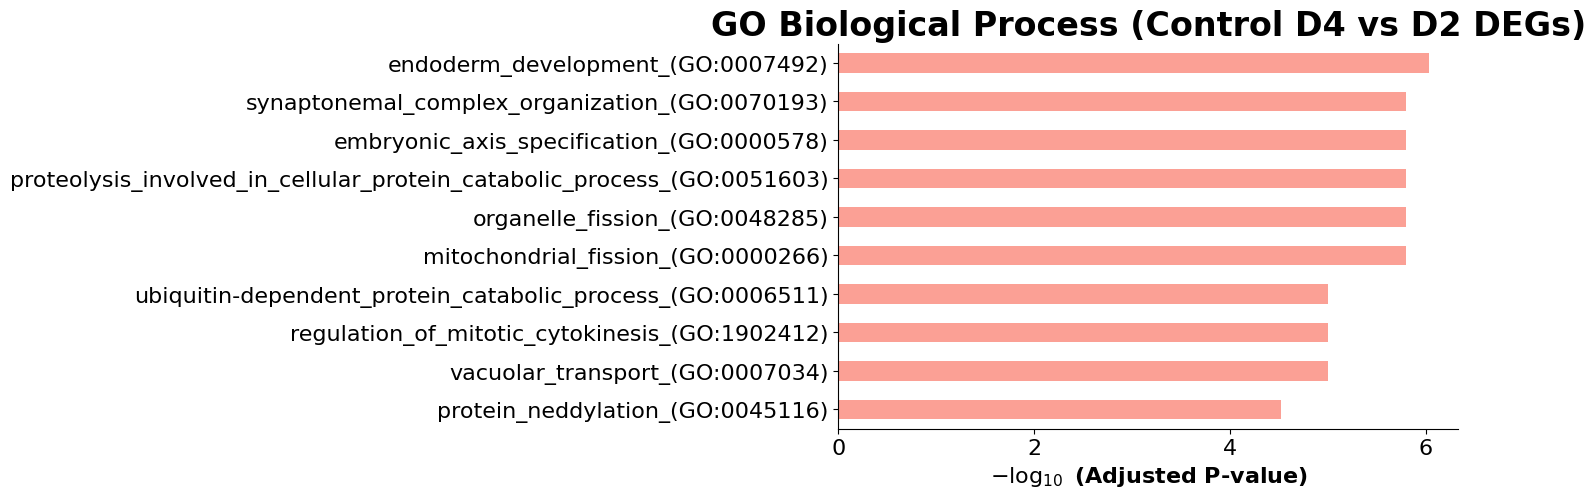

Saved GO barplot to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Control_D4_vs_D2_GO_Enrichment.png


,Term,Overlap,Adjusted P-value,Genes
0,mitochondrial_fission_(GO:0000266),12/200,0.000002,dlst-1;erfa-3;F44E7.4;mex-5;plk-3;puf-5;tcc-1;...
1,organelle_fission_(GO:0048285),12/200,0.000002,daf-18;Y73B6BL.23;F18A1.7;rnp-8;pfn-1;mex-5;pu...
2,mitotic_nuclear_division_(GO:0140014),10/200,0.000030,daf-18;rnp-8;spt-16;mex-5;spd-5;ifet-1;puf-5;n...
3,glycolytic_process_(GO:0006096),10/200,0.000030,C05C10.5;dlst-1;erfa-3;F44E7.4;pfn-1;mex-5;puf...
4,mitotic_spindle_checkpoint_(GO:0071174),9/200,0.000125,rnr-2;htp-2;spt-16;ran-1;ifet-1;rnh-2;npp-10;w...
5,negative_regulation_of_meiotic_cell_cycle_(GO:...,10/200,0.000030,daf-18;F18A1.7;rnp-8;egg-1;mex-5;ifet-1;puf-5;...
6,zymogen_activation_(GO:0031638),8/200,0.000497,rnp-8;egg-1;mex-5;ifet-1;plk-3;puf-5;tcc-1;wago-1
7,mRNA_cleavage_(GO:0006379),9/200,0.000125,rnp-8;egg-1;mex-5;ifet-1;plk-3;puf-5;tcc-1;snp...
8,lipid_homeostasis_(GO:0055088),8/200,0.000497,F18A1.7;C01G8.1;mex-5;puf-5;rbg-3;eif-2A;suco-...
9,embryonic_axis_specification_(GO:0000578),12/200,0.000002,C05C10.5;daf-18;F18A1.7;C01G8.1;rnp-8;mex-5;if...


In [33]:
import gseapy as gp
import matplotlib.pyplot as plt

# Filter significant DEGs for Control Day 4 vs Day 2
padj_col = "padj_Luciferase_D4_vs_Luciferase_D2"
lfc_col = "log2FoldChange_Luciferase_D4_vs_Luciferase_D2"

# Define significance (same as the Volcano plot)
sig_mask_d4d2 = (res_luc_d4_d2[padj_col] < 0.05) & (res_luc_d4_d2[lfc_col].abs() > 1.0)
sig_degs_d4d2 = res_luc_d4_d2[sig_mask_d4d2]
gene_list_d4d2 = sig_degs_d4d2['Symbol'].dropna().tolist()

print(f"Running GO Enrichment Analysis for {len(gene_list_d4d2)} significant DEGs (Control D4 vs D2)...")

if len(gene_list_d4d2) > 0:
    try:
        celegans_libs = gp.get_library_name(organism='celegans')
        go_lib = [lib for lib in celegans_libs if 'GO_Biological_Process' in lib]
        selected_lib = go_lib[-1] if go_lib else 'GO_Biological_Process_2018'
        print(f"Using Enrichr library: {selected_lib}")

        enr_d4d2 = gp.enrichr(
            gene_list=gene_list_d4d2,
            gene_sets=[selected_lib],
            organism='celegans',
            outdir=None
        )

        enrich_res_d4d2 = enr_d4d2.results
        sig_res_d4d2 = enrich_res_d4d2[enrich_res_d4d2['Adjusted P-value'] < 0.05]

        if not sig_res_d4d2.empty:
            print(f"Found {len(sig_res_d4d2)} significantly enriched GO terms!")
            ax = gp.barplot(enr_d4d2.results, column="Adjusted P-value", title="GO Biological Process (Control D4 vs D2 DEGs)", top_term=10, figsize=(8, 5))
            plt.tight_layout()

            go_fig_path = f'{RESULTS_DIR}/Control_D4_vs_D2_GO_Enrichment.png'
            plt.savefig(go_fig_path, dpi=300)
            plt.show()
            print(f"Saved GO barplot to {go_fig_path}")

            display(sig_res_d4d2[['Term', 'Overlap', 'Adjusted P-value', 'Genes']].head(10))
        else:
            print("No significantly enriched GO terms found (FDR < 0.05).")
            display(enrich_res_d4d2.head())

    except Exception as e:
        print(f"An error occurred during GO enrichment: {e}")
else:
    print("Not enough significant DEGs to run enrichment analysis.")

## Step 14: Co-Expression Analysis (Control L4 $\rightarrow$ Day 1 $\rightarrow$ Day 2)
To identify groups of co-regulated genes, we will extract the Control (`Luciferase`) samples from L4, Day 1, and Day 2. We will filter for genes that show dynamic changes across these stages and use **K-Means clustering** to group them into distinct temporal trajectories (e.g., continuous upregulation, transient early peak, downregulation).

Filtering for Control L4, Day 1, and Day 2 samples...
Found 26529 dynamically changing genes across L4 -> D1 -> D2.


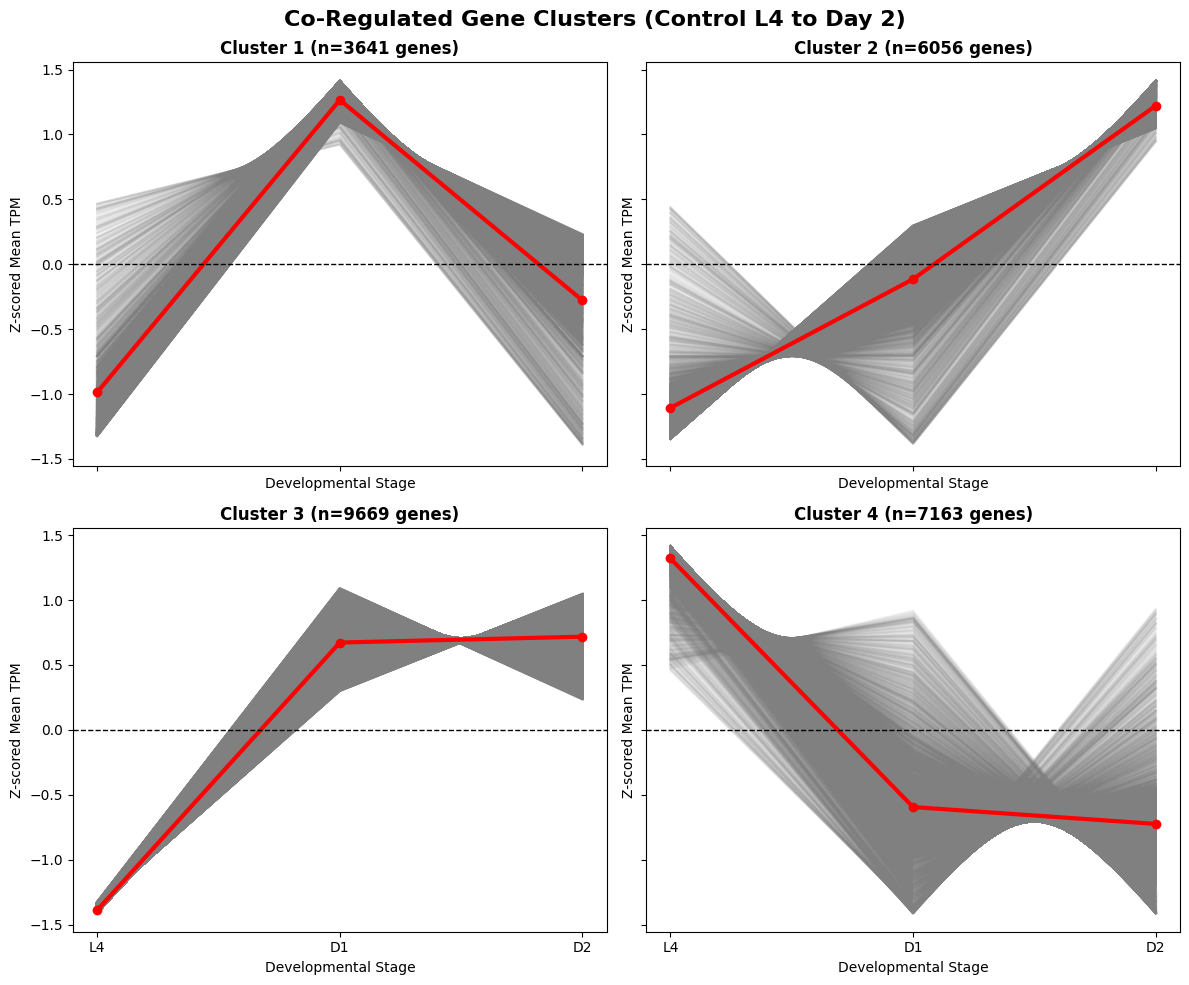

Saved clustering plot to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Coexpression_Clusters_L4_D1_D2.png

--- Cluster 1 Example Genes (first 15) ---
abf-3, cyp-14A5, ceh-24, clh-6, cyl-1, dbl-1, dhs-13, dhs-20, dop-2, dsl-7, gei-6, glc-1, grl-18, mtl-1, nex-4

--- Cluster 2 Example Genes (first 15) ---
acr-23, amx-3, apx-1, bbs-8, bir-2, cdc-25.2, che-7, cnb-1, coh-3, col-43, col-151, col-163, cpr-2, cwp-3, daf-11

--- Cluster 3 Example Genes (first 15) ---
aat-2, abf-4, abt-4, abu-8, acr-15, acr-16, acr-17, acr-18, acy-2, acy-4, aqp-5, aqp-6, avr-15, cdr-1, ceh-27

--- Cluster 4 Example Genes (first 15) ---
act-1, act-2, act-3, aip-1, air-1, akt-1, alh-4, alh-5, aos-1, apc-10, aps-1, aqp-4, arx-2, asp-1, asp-2

Saved full cluster assignments to /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Coexpression_Clusters_L4_D1_D2.csv


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from scipy.stats import zscore

print("Filtering for Control L4, Day 1, and Day 2 samples...")

# 1. Isolate relevant Control samples
stages = ['L4', 'D1', 'D2']
control_samples = manifest_df[
    (manifest_df['Condition'] == 'Luciferase') &
    (manifest_df['Stage'].isin(stages))
]['SampleName']

# 2. Subset TPM matrix and calculate mean expression per stage
tpm_control = tpm_df[control_samples]

# Pre-filter: Keep genes with a baseline level of expression (Mean TPM > 5 in these samples)
tpm_filtered = tpm_control[tpm_control.mean(axis=1) > 5.0]

mean_tpm_stage = pd.DataFrame(index=tpm_filtered.index)
for stage in stages:
    stage_samples = manifest_df[(manifest_df['Condition'] == 'Luciferase') & (manifest_df['Stage'] == stage)]['SampleName']
    mean_tpm_stage[stage] = tpm_filtered[stage_samples].mean(axis=1)

# 3. Filter for dynamic genes (Fold Change max/min > 1.5)
fold_change = (mean_tpm_stage.max(axis=1) + 0.1) / (mean_tpm_stage.min(axis=1) + 0.1)
variable_genes = mean_tpm_stage[fold_change > 1.5]

print(f"Found {len(variable_genes)} dynamically changing genes across L4 -> D1 -> D2.")

# 4. Z-score the expression for clustering (row-scaling)
z_scores = variable_genes.apply(zscore, axis=1, result_type='expand')
z_scores.columns = stages
z_scores = z_scores.dropna() # Drop any NaNs from zero variance

# 5. K-means clustering (k=4 clusters for typical time-course profiles)
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(z_scores)
z_scores['Cluster'] = clusters

# Add Gene Symbols for interpretation
z_scores['Symbol'] = [gene_id_to_symbol.get(g, g) for g in z_scores.index]

# 6. Plot the clusters
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i in range(k):
    cluster_data = z_scores[z_scores['Cluster'] == i][stages]
    ax = axes[i]

    # Plot individual genes lightly
    for _, row in cluster_data.iterrows():
        ax.plot(stages, row, color='gray', alpha=0.05)

    # Plot mean cluster trajectory
    ax.plot(stages, cluster_data.mean(axis=0), color='red', linewidth=3, marker='o')

    ax.set_title(f'Cluster {i + 1} (n={len(cluster_data)} genes)', fontweight='bold')
    ax.set_ylabel('Z-scored Mean TPM')
    ax.set_xlabel('Developmental Stage')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)

plt.suptitle("Co-Regulated Gene Clusters (Control L4 to Day 2)", fontsize=16, fontweight='bold')
plt.tight_layout()

cluster_fig_path = f"{RESULTS_DIR}/Coexpression_Clusters_L4_D1_D2.png"
plt.savefig(cluster_fig_path, dpi=300)
plt.show()
print(f"Saved clustering plot to: {cluster_fig_path}")

# 7. Show example genes in each cluster and save
for i in range(k):
    cluster_genes = z_scores[z_scores['Cluster'] == i]['Symbol'].tolist()
    print(f"\n--- Cluster {i + 1} Example Genes (first 15) ---")
    print(", ".join(cluster_genes[:15]))

cluster_csv_path = f"{RESULTS_DIR}/Coexpression_Clusters_L4_D1_D2.csv"
z_scores.to_csv(cluster_csv_path)
print(f"\nSaved full cluster assignments to {cluster_csv_path}")

### Cluster Expression Profiles Across All Conditions
Now, we track the genes from each of the 4 clusters defined above and plot their mean trajectory across **all** stages (L4 $\rightarrow$ D4) in both the Control (`Luciferase`) and `cbd-1` RNAi cohorts.

Mapping the 4 Control-defined clusters across all experimental conditions...


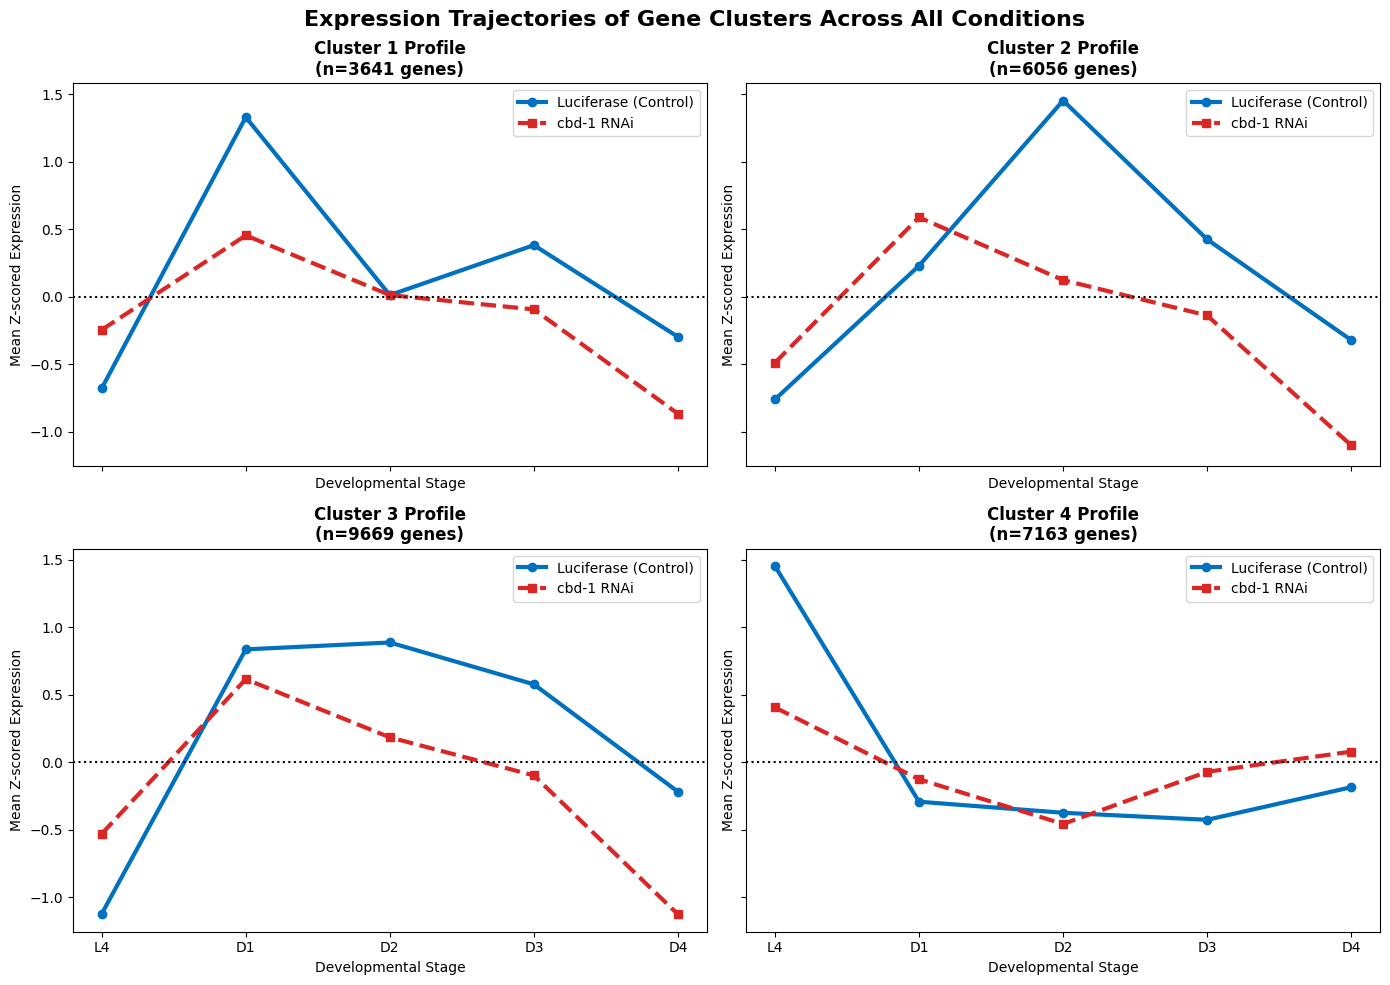

Saved cluster comparison plot to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Cluster_Profiles_All_Conditions.png


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

print("Mapping the 4 Control-defined clusters across all experimental conditions...")

if 'z_scores' in locals() and 'Cluster' in z_scores.columns:
    k = 4
    # Define the chronological group order
    groups = [
        'Luciferase_L4', 'Luciferase_D1', 'Luciferase_D2', 'Luciferase_D3', 'Luciferase_D4',
        'cbd_1_RNAi_L4', 'cbd_1_RNAi_D1', 'cbd_1_RNAi_D2', 'cbd_1_RNAi_D3', 'cbd_1_RNAi_D4'
    ]

    # Filter to groups that actually exist in the manifest
    valid_groups = [g for g in groups if g in manifest_df['Group'].unique()]

    # Calculate mean TPM per group for the dynamically changing genes
    mean_tpm_all = pd.DataFrame()
    for g in valid_groups:
        samples = manifest_df[manifest_df['Group'] == g]['SampleName']
        mean_tpm_all[g] = tpm_df.loc[z_scores.index, samples].mean(axis=1)

    # Row-scale (Z-score) across ALL conditions to highlight relative peaks
    z_tpm_all = mean_tpm_all.apply(zscore, axis=1, result_type='expand')
    z_tpm_all.columns = mean_tpm_all.columns
    z_tpm_all['Cluster'] = z_scores['Cluster']

    # Plotting
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
    axes = axes.flatten()

    stages = ['L4', 'D1', 'D2', 'D3', 'D4']

    for i in range(k):
        ax = axes[i]
        cluster_genes = z_tpm_all[z_tpm_all['Cluster'] == i]

        # Extract group means for the stages
        luc_cols = [f'Luciferase_{s}' for s in stages if f'Luciferase_{s}' in z_tpm_all.columns]
        cbd_cols = [f'cbd_1_RNAi_{s}' for s in stages if f'cbd_1_RNAi_{s}' in z_tpm_all.columns]

        luc_means = cluster_genes[luc_cols].mean(axis=0)
        cbd_means = cluster_genes[cbd_cols].mean(axis=0)

        # Plot trajectories
        ax.plot(stages, luc_means, color='#0070C0', linewidth=3, marker='o', label='Luciferase (Control)')
        ax.plot(stages, cbd_means, color='#DC2626', linewidth=3, marker='s', linestyle='--', label='cbd-1 RNAi')

        ax.set_title(f'Cluster {i + 1} Profile\n(n={len(cluster_genes)} genes)', fontweight='bold')
        ax.set_ylabel('Mean Z-scored Expression')
        ax.set_xlabel('Developmental Stage')
        ax.axhline(0, color='black', linestyle=':', linewidth=1.5)
        ax.legend(loc='best')

    plt.suptitle("Expression Trajectories of Gene Clusters Across All Conditions", fontsize=16, fontweight='bold')
    plt.tight_layout()

    comp_fig_path = f"{RESULTS_DIR}/Cluster_Profiles_All_Conditions.png"
    plt.savefig(comp_fig_path, dpi=300)
    plt.show()
    print(f"Saved cluster comparison plot to: {comp_fig_path}")

else:
    print("Clustering results not found. Please ensure the clustering step was run successfully.")

Generating classic Eisen-style / Gasch et al. (2000) green-black-red clustered heatmap...


/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


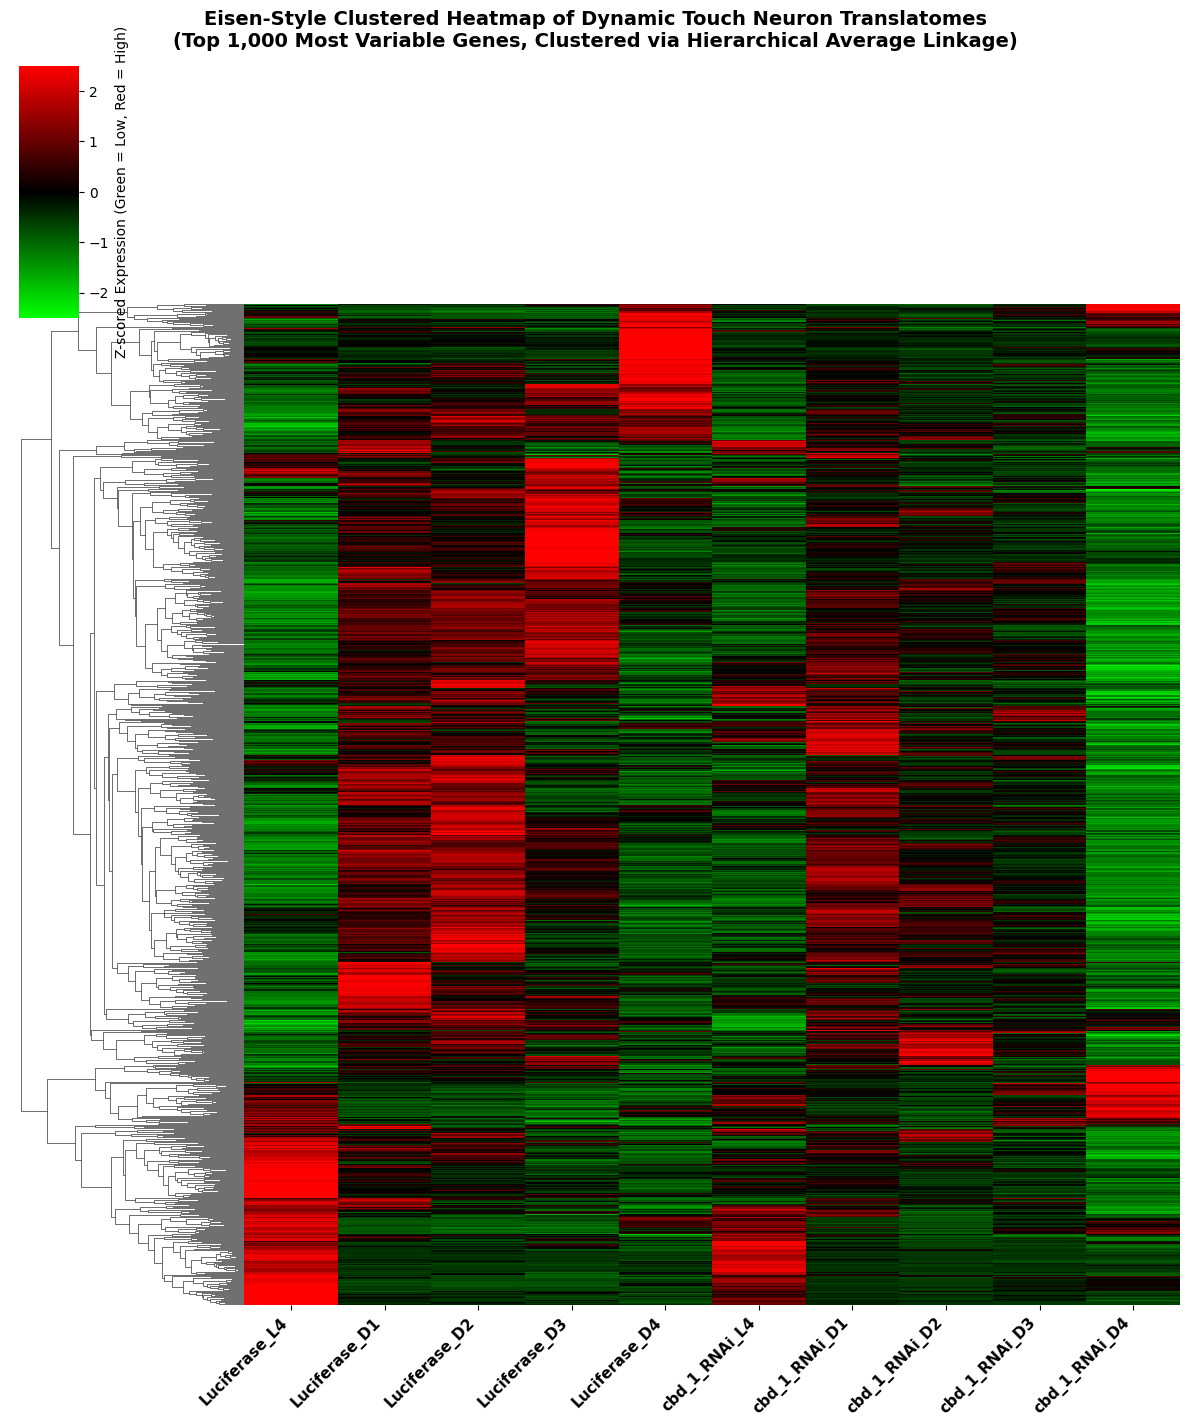

Success! Saved Eisen-style clustered heatmap to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Eisen_Style_Coexpression_Heatmap.png


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
import matplotlib.colors as mcolors

print("Generating classic Eisen-style / Gasch et al. (2000) green-black-red clustered heatmap...")

if 'z_scores' in locals() and 'Cluster' in z_scores.columns:
    # 1. Define chronological columns
    stages = ['L4', 'D1', 'D2', 'D3', 'D4']
    all_cols = [
        'Luciferase_L4', 'Luciferase_D1', 'Luciferase_D2', 'Luciferase_D3', 'Luciferase_D4',
        'cbd_1_RNAi_L4', 'cbd_1_RNAi_D1', 'cbd_1_RNAi_D2', 'cbd_1_RNAi_D3', 'cbd_1_RNAi_D4'
    ]
    valid_cols = [col for col in all_cols if col in z_tpm_all.columns]

    # 2. Extract expression data (without cluster label) for dynamic genes
    heatmap_data = z_tpm_all[valid_cols].copy()

    # Replace gene IDs with gene symbols where possible
    heatmap_data.index = [gene_id_to_symbol.get(g, g) for g in heatmap_data.index]

    # 3. Downsample to top 1,000 most variable genes to allow clean hierarchical rendering
    # (Otherwise 26,000+ rows will crash memory or render as an illegible black block)
    row_variance = heatmap_data.var(axis=1)
    top_var_genes = row_variance.nlargest(1000).index
    subset_data = heatmap_data.loc[top_var_genes]

    # 4. Create the classic Eisen green-black-red custom diverging colormap
    # Green (-3.0) -> Black (0.0) -> Red (+3.0)
    eisen_cmap = mcolors.LinearSegmentedColormap.from_list(
        'eisen_green_black_red',
        ['#00FF00', '#000000', '#FF0000'],
        N=256
    )

    # 5. Generate hierarchical cluster map with dendrograms
    g = sns.clustermap(
        subset_data,
        method='average',
        metric='euclidean',
        cmap=eisen_cmap,
        center=0.0,
        vmin=-2.5,
        vmax=2.5,
        col_cluster=False,  # Keep chronological developmental timeline intact
        row_cluster=True,    # Cluster genes hierarchically
        figsize=(12, 14),
        yticklabels=False,   # Hide individual gene names as 1000 lines will overlap
        cbar_kws={'label': 'Z-scored Expression (Green = Low, Red = High)'}
    )

    # Beautify labels
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right', fontsize=11, fontweight='bold')
    g.fig.suptitle("Eisen-Style Clustered Heatmap of Dynamic Touch Neuron Translatomes\n(Top 1,000 Most Variable Genes, Clustered via Hierarchical Average Linkage)", y=1.02, fontsize=14, fontweight='bold')

    # Save the publication-grade figure
    eisen_fig_path = f"{RESULTS_DIR}/Eisen_Style_Coexpression_Heatmap.png"
    plt.savefig(eisen_fig_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Success! Saved Eisen-style clustered heatmap to: {eisen_fig_path}")
else:
    print("Error: Missing z_scores or cluster results. Please execute the clustering step first.")

In [39]:
import pandas as pd
import os

# Ensure the clustering and heatmap data exist
if 'subset_data' in locals():
    # Re-extract the top 1,000 most variable genes used in the heatmap
    heatmap_genes_df = subset_data.copy()

    # Add corresponding gene symbols as a column
    heatmap_genes_df['Gene_Symbol'] = heatmap_genes_df.index

    # If the original Ensembl/WormBase gene IDs are needed, map them back
    # Creating a reverse mapping dictionary from symbol back to Gene ID
    symbol_to_id = {v: k for k, v in gene_id_to_symbol.items()}
    heatmap_genes_df['WormBase_Gene_ID'] = [symbol_to_id.get(sym, sym) for sym in heatmap_genes_df.index]

    # Reorder columns to make it clean
    cols = ['WormBase_Gene_ID', 'Gene_Symbol'] + [c for c in heatmap_genes_df.columns if c not in ['WormBase_Gene_ID', 'Gene_Symbol']]
    heatmap_genes_df = heatmap_genes_df[cols]

    # Save to a dedicated CSV file
    output_heatmap_csv = f"{RESULTS_DIR}/Heatmap_Top1000_Variable_Genes.csv"
    heatmap_genes_df.to_csv(output_heatmap_csv, index=False)

    print(f"Successfully extracted and saved the 1,000 heatmap genes to: {output_heatmap_csv}")
    display(heatmap_genes_df.head(10))
else:
    print("Error: Heatmap subset data not found in kernel memory. Please ensure cell 1af9bdad has been executed.")

Successfully extracted and saved the 1,000 heatmap genes to: /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Heatmap_Top1000_Variable_Genes.csv


,WormBase_Gene_ID,Gene_Symbol,Luciferase_L4,Luciferase_D1,Luciferase_D2,Luciferase_D3,Luciferase_D4,cbd_1_RNAi_L4,cbd_1_RNAi_D1,cbd_1_RNAi_D2,cbd_1_RNAi_D3,cbd_1_RNAi_D4
ilys-5,WBGene00017691,ilys-5,2.098001,-0.873568,-0.953757,-0.905368,0.445301,1.309765,-0.621228,-0.543706,-0.482506,0.527066
elo-2,WBGene00001240,elo-2,1.957477,-0.223934,-0.638744,-0.746037,-0.496868,2.002149,-0.383599,-0.631707,-0.428123,-0.410614
21ur-11294,WBGene00169640,21ur-11294,-1.117460,0.591673,2.096122,0.855038,0.705631,-0.961009,0.041862,-0.494227,-0.600170,-1.117460
21ur-8469,WBGene00171644,21ur-8469,-0.524482,2.906614,-0.246202,0.340021,-0.339513,-0.524482,-0.256081,-0.306912,-0.524482,-0.524482
eif-2Bepsilon,WBGene00008428,eif-2Bepsilon,2.577336,-0.538948,-0.844814,-0.759728,-0.645753,0.744699,-0.500655,-0.617891,0.307102,0.278651
act-2,WBGene00000064,act-2,1.231392,-0.925303,-1.009657,-1.054400,-0.366284,0.934263,-0.555616,-0.524164,0.319432,1.950337
act-3,WBGene00000065,act-3,2.422454,-0.698353,-0.740883,-0.805845,-0.099225,1.294332,-0.471959,-0.636198,-0.353699,0.089376
apx-1,WBGene00000168,apx-1,-1.260346,0.286309,1.266008,1.437544,0.271894,-0.871619,0.800272,0.362604,-0.684529,-1.608137
asp-1,WBGene00000214,asp-1,1.437253,-0.713746,-0.820129,-0.798855,-0.379708,2.313558,-0.301310,-0.530994,-0.437242,0.231171
col-150,WBGene00000723,col-150,1.857238,-0.568555,-0.560701,-0.522606,-0.505160,2.128179,-0.484755,-0.559826,-0.391036,-0.392777


In [36]:
import os
import pandas as pd

# Ensure z_scores exists with Cluster column
if 'z_scores' in locals() and 'Cluster' in z_scores.columns:
    # 1. Save individual cluster files
    for cluster_id in sorted(z_scores['Cluster'].unique()):
        cluster_subset = z_scores[z_scores['Cluster'] == cluster_id][['Symbol']]
        # Map internal 0-indexed to standard 1-4 naming convention
        cluster_name = f"Cluster_{cluster_id + 1}"
        out_path = f"{RESULTS_DIR}/{cluster_name}_Gene_List.csv"

        cluster_subset.to_csv(out_path)
        print(f"Saved {len(cluster_subset)} genes belonging to {cluster_name} -> {out_path}")

    # 2. Save a unified lookup file
    unified_path = f"{RESULTS_DIR}/Coexpression_All_Clusters_Assigned.csv"
    unified_df = z_scores[['Symbol', 'Cluster']].copy()
    unified_df['Cluster'] = unified_df['Cluster'] + 1  # 1-indexed for presentation
    unified_df.to_csv(unified_path)
    print(f"\nSaved unified cluster assignment file with {len(unified_df)} genes -> {unified_path}")
else:
    print("Could not find the K-Means 'z_scores' cluster DataFrame in the environment. Please run the clustering cell first.")

Saved 3641 genes belonging to Cluster_1 -> /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Cluster_1_Gene_List.csv
Saved 6056 genes belonging to Cluster_2 -> /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Cluster_2_Gene_List.csv
Saved 9669 genes belonging to Cluster_3 -> /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Cluster_3_Gene_List.csv
Saved 7163 genes belonging to Cluster_4 -> /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Cluster_4_Gene_List.csv

Saved unified cluster assignment file with 26529 genes -> /content/drive/MyDrive/ZB5886_TRAPseq/DESeq2_Results/Coexpression_All_Clusters_Assigned.csv
